# Trajectory Analysis

Analysis of D1–D8 taxonomy categories and Explicit/Contextual decision visibility in Terminal-Bench 2.1 trajectories.

1. GPT 300 Analysis — V1: annotations in the final V1 workbook.
2. GPT 300 Analysis — V2: annotations in the final V2 workbook.
3. Manual 300 Analysis: annotations in the final manual workbook.
4. V1 and V2 against manual ground truth: step-level precision, recall, and F1.
5. Annotation error checks: raw taxonomy/visibility values and missing paired fields.
6. V1 and V2 against manual ground truth: trajectory-level set comparison, ignoring step positions.

The three input workbooks are read from `outputs/Final Annotations`. The model and harness identify the agent that produced each trajectory. Source workbooks are read only; no LLM calls or new annotations are generated.


### Shared setup and sources

The V1, V2, and manual inputs are selected explicitly from `outputs/Final Annotations`. Workbook filenames define the analysis versions; older copies elsewhere in the project are not used. Paths are resolved from the repository root. Required packages: pandas, matplotlib and openpyxl.


In [50]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from openpyxl import load_workbook

def find_project_root():
    current = Path.cwd().resolve()
    for parent in (current, *current.parents):
        candidates = (parent, parent / "design-decisions-by-LLMs")
        for candidate in candidates:
            if (candidate / "notebooks").is_dir() and (candidate / "annotations").is_dir():
                return candidate
    raise FileNotFoundError("Project root not found. Open the notebook from the repository.")

PROJECT_ROOT = find_project_root()
INPUT_DIR = PROJECT_ROOT / "outputs" / "Final Annotations"
V1_WORKBOOK_PATH = INPUT_DIR / "terminalbench21_task_annotated_v1.xlsx"
V2_WORKBOOK_PATH = INPUT_DIR / "TerminalBench21_task_annotated_v2.xlsx"
MANUAL_WORKBOOK_PATH = INPUT_DIR / "terminalbench21_task_annotated_manual.xlsx"
WORKBOOK_PATHS = {
    "GPT 300 V1": V1_WORKBOOK_PATH,
    "GPT 300 V2": V2_WORKBOOK_PATH,
    "Manual 300": MANUAL_WORKBOOK_PATH,
}
for source_name, workbook_path in WORKBOOK_PATHS.items():
    if not workbook_path.is_file():
        raise FileNotFoundError(f"{source_name}: {workbook_path}")

CATEGORY_NAMES = {
    "D1": "Diagnostic or analytical strategy",
    "D2": "Algorithm or optimization strategy",
    "D3": "Representation or architecture choice",
    "D4": "Parameter or configuration choice",
    "D5": "Implementation or computational-efficiency choice",
    "D6": "Recovery or strategy revision",
    "D7": "Verification choice",
    "D8": "Termination or submission choice",
}
CATEGORIES = list(CATEGORY_NAMES)
VISIBILITIES = ["Explicit", "Contextual"]
CATEGORY_COLORS = ["#4E79A7", "#F28E2B", "#59A14F", "#B07AA1",
                   "#76B7B2", "#E15759", "#EDC948", "#9C755F"]
VISIBILITY_COLORS = ["#4E79A7", "#F28E2B"]

plt.rcParams.update({
    "figure.figsize": (11, 5),
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
display(pd.DataFrame(
    [{"Analysis": name, "Workbook": str(path)} for name, path in WORKBOOK_PATHS.items()]
))
display(pd.DataFrame(CATEGORY_NAMES.items(), columns=["Category", "Definition"]));

,Analysis,Workbook
0,GPT 300 V1,D:\Studies\UZH-M.Sc\THESIS\design-decisions-by...
1,GPT 300 V2,D:\Studies\UZH-M.Sc\THESIS\design-decisions-by...
2,Manual 300,D:\Studies\UZH-M.Sc\THESIS\design-decisions-by...


,Category,Definition
0,D1,Diagnostic or analytical strategy
1,D2,Algorithm or optimization strategy
2,D3,Representation or architecture choice
3,D4,Parameter or configuration choice
4,D5,Implementation or computational-efficiency choice
5,D6,Recovery or strategy revision
6,D7,Verification choice
7,D8,Termination or submission choice


### Shared annotation reader

Each worksheet represents a task and each data row a recorded step. Newline-separated decisions are retained in order. Space-separated category codes such as `D2 D5` count as two **category assignments**, not necessarily two independent decisions.

The shared reader handles capitalization and the observed spelling variants `Contexual` and `Contextuall`. Shared or repeated visibility labels are applied uniformly only when all labels are identical and valid. These adjustments are listed for review and never written back to Excel.

Missing, unsupported or ambiguously aligned visibility is excluded from visibility percentages; valid categories remain in D1–D8 totals. Only **Explicit** and **Contextual** appear in visibility distributions. Counts describe recorded annotation entries, not independently verified or deduplicated decision events.

In [51]:
def canonical_model(value):
    name = str(value or "").strip().lower()
    prefixes = ("anthropic/", "openai/", "gemini/", "vertex_ai/", "xai/", "cursor/")
    changed = True
    while changed:
        changed = False
        for prefix in prefixes:
            if name.startswith(prefix):
                name = name[len(prefix):]
                changed = True
    return name.removesuffix(":cloud")

def split_entries(value):
    return [part.strip() for part in str(value or "").splitlines() if part.strip()]

ENTRY_COLUMNS = [
    "task", "trial_id", "model", "harness", "resolved", "step", "excel_row",
    "has_category", "entry_number", "category", "visibility",
]
ISSUE_COLUMNS = ["Task", "Excel row", "Issue", "Category cell", "Visibility cell"]

def parse_categories(value):
    text = str(value or "").strip()
    pattern = r"(?<![A-Za-z0-9])D[1-8](?![A-Za-z0-9])"
    categories = [v.upper() for v in re.findall(pattern, text, flags=re.I)]
    remainder = re.sub(pattern, "", text, flags=re.I)
    if remainder.strip(" \t\r\n,;/|"):
        raise ValueError(f"Unsupported taxonomy text: {text!r}")
    return categories

def parse_visibility(value):
    text = str(value or "").strip()
    tokens = re.split(r"[\s,;/|]+", text) if text else []
    aliases = {"explicit": "Explicit", "contextual": "Contextual",
               "contexual": "Contextual", "contextuall": "Contextual"}
    return [aliases.get(token.lower(), token) for token in tokens]

def read_annotation_workbook(workbook_path, task_names=None):
    workbook_path = Path(workbook_path)
    if not workbook_path.is_file():
        raise FileNotFoundError(workbook_path)
    step_records, entry_records, issue_records = [], [], []
    book = load_workbook(workbook_path, read_only=True, data_only=False)
    try:
        tasks = list(task_names) if task_names is not None else book.sheetnames
        missing = set(tasks) - set(book.sheetnames)
        if missing:
            raise ValueError(f"Missing task sheets: {sorted(missing)}")
        for task in tasks:
            sheet = book[task]
            required = {"Model", "Harness", "Trial ID", "Step", "Taxonomy category", "Visibility"}
            header_row, columns = None, None
            for number, values in enumerate(sheet.iter_rows(min_row=1, max_row=20, values_only=True), 1):
                headers = {str(v).strip(): i for i, v in enumerate(values) if v is not None}
                if required.issubset(headers):
                    header_row, columns = number, headers
                    break
            if header_row is None:
                raise ValueError(f"Required headers not found in {task!r}.")
            for excel_row, values in enumerate(
                sheet.iter_rows(min_row=header_row + 1, values_only=True), header_row + 1
            ):
                def get(label):
                    i = columns.get(label)
                    return values[i] if i is not None and i < len(values) else None
                trial_id, step_value = str(get("Trial ID") or "").strip(), get("Step")
                if not trial_id or step_value is None or str(step_value).strip() == "":
                    continue
                step = str(step_value).strip()
                if isinstance(step_value, (int, float)) and float(step_value).is_integer():
                    step = str(int(step_value))
                raw_category, raw_visibility = get("Taxonomy category"), get("Visibility")
                try:
                    categories = parse_categories(raw_category)
                except ValueError as error:
                    raise ValueError(f"{task}!L{excel_row}: {error}") from error
                visibilities = parse_visibility(raw_visibility)
                base = {
                    "task": task, "trial_id": trial_id,
                    "model": canonical_model(get("Model")) or "Not recorded",
                    "harness": str(get("Harness") or "").strip().lower() or "Not recorded",
                    "resolved": str(get("Resolved") or "").strip(),
                    "step": step, "excel_row": excel_row, "has_category": bool(categories),
                }
                step_records.append(base)
                def note(message):
                    issue_records.append({
                        "Task": task, "Excel row": excel_row, "Issue": message,
                        "Category cell": raw_category, "Visibility cell": raw_visibility,
                    })
                if not categories:
                    if visibilities:
                        note("Visibility without a taxonomy assignment; excluded")
                    continue
                if categories != split_entries(raw_category):
                    note("Category formatting normalized for counting")
                if visibilities != split_entries(raw_visibility):
                    note("Visibility spelling/separators normalized")
                if not visibilities:
                    paired = [None] * len(categories)
                    note("Missing visibility; categories retained, visibility excluded")
                elif any(v not in VISIBILITIES for v in visibilities):
                    paired = [None] * len(categories)
                    note("Unsupported visibility; categories retained, visibility excluded")
                elif len(categories) == len(visibilities):
                    paired = visibilities
                elif len(set(visibilities)) == 1:
                    paired = [visibilities[0]] * len(categories)
                    note("Shared or repeated identical visibility applied uniformly")
                else:
                    paired = [None] * len(categories)
                    note("Ambiguous category/visibility alignment; visibility excluded")
                for number, (category, visibility) in enumerate(zip(categories, paired), 1):
                    entry_records.append({**base, "entry_number": number,
                                          "category": category, "visibility": visibility})
    finally:
        book.close()
    selected_steps = pd.DataFrame(step_records)
    selected_entries = pd.DataFrame(entry_records, columns=ENTRY_COLUMNS)
    if selected_steps.empty:
        raise ValueError("No usable trajectory rows found.")
    if selected_steps.duplicated(["task", "trial_id", "step"]).any():
        raise ValueError("Duplicate task + trajectory + step keys found.")
    if selected_steps.groupby(["task", "trial_id"])[
        ["model", "harness", "resolved"]
    ].nunique().gt(1).any().any():
        raise ValueError("Inconsistent model, harness or outcome within a trajectory.")
    trials = selected_steps.groupby(
        ["task", "trial_id", "model", "harness", "resolved"], dropna=False
    ).size().rename("recorded_steps").reset_index()
    counts = selected_entries.groupby(["task", "trial_id"]).size().rename("annotation_entries")
    trials = trials.merge(counts, on=["task", "trial_id"], how="left")
    trials["annotation_entries"] = trials["annotation_entries"].fillna(0).astype(int)
    return {"steps": selected_steps, "entries": selected_entries, "trajectories": trials,
            "issues": pd.DataFrame(issue_records, columns=ISSUE_COLUMNS)}



### Shared setup for the full 300-trajectory samples

Every section includes all task sheets and trajectories in its workbook. No task-subset filtering is applied.

The V2 and manual sections verify that their task, Trial ID, step, model, harness, and outcome identities match V1 before analysis. This verifies sample alignment, not annotation agreement or manual-review completeness.

Only Explicit and Contextual appear in visibility distributions. Missing or ambiguous visibility is excluded and reported for review; its category assignments remain in D1–D8 totals. Formatting normalization does not revise Excel annotations.


In [52]:
EXPECTED_TRAJECTORIES = 300

def read_full_sample(workbook_path):
    data = read_annotation_workbook(workbook_path)
    trajectory_count = len(data["trajectories"])
    if trajectory_count != EXPECTED_TRAJECTORIES:
        raise ValueError(
            f"{Path(workbook_path).name}: expected {EXPECTED_TRAJECTORIES} trajectories, "
            f"found {trajectory_count}. Check the selected workbook."
        )
    return data


### Shared analysis methods

All three sections use the same calculations and layout. A category count is a taxonomy assignment in an annotated step; multiple assignments in a cell are counted separately, not assumed to be separate decision events. Annotated step rows and category annotation entries are reported separately.

D1–D8 percentages are calculated within each model or harness: category count divided by that row's total D1–D8 assignments × 100. Visibility percentages use only Explicit and Contextual entries. Rows with no eligible annotations have undefined percentages, not zero.

These are annotation-weighted distributions, not success rates or equal-weight averages over trajectories. The workbooks describe the same source trajectories under different annotation versions and are not independent datasets. Small groups and task composition limit model/harness comparisons. Blank manual annotation cells do not, by themselves, establish that a step was reviewed.


In [53]:
def annotation_coverage(data, group):
    return data["trajectories"].groupby(group, dropna=False).agg(
        trajectories=("trial_id", "size"), tasks=("task", "nunique"),
        trajectories_with_entries=("annotation_entries", lambda x: int(x.gt(0).sum())),
        annotation_entries=("annotation_entries", "sum"),
        mean_entries_per_trajectory=("annotation_entries", "mean"),
        median_entries_per_trajectory=("annotation_entries", "median"),
    ).sort_index()

def annotation_distribution(data, group, field, order):
    coverage = annotation_coverage(data, group)
    eligible = data["entries"].loc[data["entries"][field].isin(order)]
    row_groups = [eligible[name] for name in group] if isinstance(group, list) else eligible[group]
    counts = pd.crosstab(row_groups, eligible[field]).reindex(
        index=coverage.index, columns=order, fill_value=0
    )
    denominator = counts.sum(axis=1)
    percentages = counts.div(denominator.where(denominator.ne(0)), axis=0).mul(100)
    return counts, percentages

def show_distribution_tables(counts, percentages, title):
    print(f"{title} — annotation counts")
    display(counts)
    print(f"{title} — within-row distribution (%)")
    display(percentages.round(2).rename(columns=lambda column: f"{column} (%)"))

def annotation_overall(data, field, order):
    counts = data["entries"][field].value_counts().reindex(order, fill_value=0)
    denominator = int(counts.sum())
    percentages = 100 * counts / denominator if denominator else counts.astype(float) * float("nan")
    return pd.DataFrame({"Annotation entries": counts, "Distribution (%)": percentages})

def show_overview(data, source):
    display(pd.Series({
        "Tasks": data["trajectories"]["task"].nunique(),
        "Trajectories": len(data["trajectories"]),
        "Trajectory models": data["trajectories"]["model"].nunique(),
        "Harnesses": data["trajectories"]["harness"].nunique(),
        "Recorded step rows": len(data["steps"]),
        "Step rows with taxonomy annotations": int(data["steps"]["has_category"].sum()),
        "Category annotation entries": len(data["entries"]),
        "Trajectories with no annotation entries": int(data["trajectories"]["annotation_entries"].eq(0).sum()),
        "Entries included in visibility analysis": int(data["entries"]["visibility"].isin(VISIBILITIES).sum()),
    }, name=source).to_frame())
    for group in ["task", "model", "harness"]:
        print(f"{source}: coverage by {group}")
        display(annotation_coverage(data, group).round(2))

def show_overall_distribution(data, source, field):
    order, colors = (CATEGORIES, CATEGORY_COLORS) if field == "category" else (VISIBILITIES, VISIBILITY_COLORS)
    table = annotation_overall(data, field, order)
    label = "D1–D8" if field == "category" else "Explicit and contextual visibility"
    print(f"{source}: {label} — overall counts and percentages")
    display(table.round(2))
    if not table["Annotation entries"].sum():
        print(f"{source}: no eligible {field} annotations.")
        return
    ax = table["Annotation entries"].plot.bar(color=colors, rot=0, figsize=(11, 4.5))
    ax.set(title=f"{source}: {label}", xlabel=field.capitalize(), ylabel="Annotation entries")
    ax.bar_label(ax.containers[0], padding=3)
    ax.margins(y=0.15)
    plt.tight_layout()
    plt.show()

def plot_group_distribution(data, source, group, field, percentages):
    coverage = annotation_coverage(data, group)
    counts, _ = annotation_distribution(data, group, field, list(percentages.columns))
    active = percentages.dropna(how="all").copy()
    if active.empty:
        print(f"{source}: no eligible {field} annotations.")
        return
    active.index = [
        f"{name} (n={int(coverage.loc[name, 'trajectories'])}, entries={int(counts.loc[name].sum())})"
        for name in active.index
    ]
    colors = CATEGORY_COLORS if field == "category" else VISIBILITY_COLORS
    label = "D1–D8" if field == "category" else "Decision visibility"
    ax = active.plot.barh(stacked=True, color=colors,
                         figsize=(13, max(4, 0.62 * len(active))), width=0.75)
    ax.invert_yaxis()
    ax.set(title=f"{source}: {label} by {group}",
           xlabel="Share of annotation entries within group (%)",
           ylabel=group.capitalize(), xlim=(0, 100))
    for container in ax.containers:
        ax.bar_label(container, labels=[f"{v:.0f}%" if v >= 6 else "" for v in container.datavalues],
                     label_type="center", fontsize=9)
    ax.legend(title=field.capitalize(), bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

def show_group_distribution(data, source, group, field):
    order = CATEGORIES if field == "category" else VISIBILITIES
    counts, percentages = annotation_distribution(data, group, field, order)
    label = "D1–D8" if field == "category" else "Explicit/Contextual"
    show_distribution_tables(counts, percentages, f"{source}: {label} by {group}")
    plot_group_distribution(data, source, group, field, percentages)

def show_combinations(data, source):
    print(f"{source}: model × harness coverage")
    display(annotation_coverage(data, ["harness", "model"]).round(2))
    for field, order in [("category", CATEGORIES), ("visibility", VISIBILITIES)]:
        counts, percentages = annotation_distribution(data, ["harness", "model"], field, order)
        label = "D1–D8" if field == "category" else "Explicit/Contextual"
        show_distribution_tables(counts, percentages, f"{source}: {label} by harness × model")

def annotation_group_summary(data, group):
    coverage = annotation_coverage(data, group)
    category_counts, category_percentages = annotation_distribution(data, group, "category", CATEGORIES)
    visibility_counts, visibility_percentages = annotation_distribution(data, group, "visibility", VISIBILITIES)
    result = coverage[["trajectories", "tasks", "annotation_entries",
                       "mean_entries_per_trajectory", "median_entries_per_trajectory"]].copy()
    result["most_frequent_category"] = [
        row.idxmax() if row.sum() else "No annotations"
        for _, row in category_counts.iterrows()
    ]
    result["most_frequent_category_pct"] = category_percentages.max(axis=1)
    result["valid_visibility_entries"] = visibility_counts.sum(axis=1)
    result["explicit_pct"] = visibility_percentages["Explicit"]
    result["contextual_pct"] = visibility_percentages["Contextual"]
    return result.round(2)

def show_findings(data, source):
    category_table = annotation_overall(data, "category", CATEGORIES)
    visibility_table = annotation_overall(data, "visibility", VISIBILITIES)
    print(f"{source}: {len(data['trajectories']):,} trajectories across "
          f"{data['trajectories']['task'].nunique()} tasks; {len(data['entries']):,} category annotation entries.")
    if category_table["Annotation entries"].sum():
        top = category_table["Annotation entries"].idxmax()
        print(f"Most frequent category: {top} — {CATEGORY_NAMES[top]} "
              f"({int(category_table.loc[top, 'Annotation entries']):,} entries; "
              f"{category_table.loc[top, 'Distribution (%)']:.2f}%).")
    valid_visibility = int(visibility_table["Annotation entries"].sum())
    print(f"Visibility denominator: {valid_visibility:,} valid entries.")
    if valid_visibility:
        print(f"Visibility: {visibility_table.loc['Explicit', 'Distribution (%)']:.2f}% Explicit; "
              f"{visibility_table.loc['Contextual', 'Distribution (%)']:.2f}% Contextual.")
    for group in ["model", "harness"]:
        print(f"{source}: summary by {group}")
        display(annotation_group_summary(data, group))

def show_annotation_checks(data, source):
    excluded = int((~data["entries"]["visibility"].isin(VISIBILITIES)).sum())
    print(f"{source}: {excluded} category entries excluded from visibility distributions.")
    if not data["issues"].empty:
        display(data["issues"].reset_index(drop=True))
    else:
        print(f"{source}: no annotation formatting issues found.")

def check_same_sample(reference_data, candidate_data, source, reference_name="V1"):
    columns = ["task", "trial_id", "step", "model", "harness", "resolved"]
    keys = ["task", "trial_id", "step"]
    reference_rows = reference_data["steps"][columns].set_index(keys).sort_index()
    candidate_rows = candidate_data["steps"][columns].set_index(keys).sort_index()
    if not reference_rows.equals(candidate_rows):
        raise ValueError(
            f"{source} and {reference_name} trajectory rows differ. "
            "Compare workbook inputs before interpreting results."
        )
    print(
        f"{source} and {reference_name} cover the same {len(reference_data['trajectories']):,} "
        "trajectories and recorded steps."
    )


## 1. GPT 300 Analysis — V1

The final V1 workbook contains the full 300-trajectory sample. All analyses below use its annotations.


In [54]:
gpt_v1 = read_full_sample(V1_WORKBOOK_PATH)
show_annotation_checks(gpt_v1, "GPT 300 V1")


GPT 300 V1: 0 category entries excluded from visibility distributions.
GPT 300 V1: no annotation formatting issues found.


### 1.1 Dataset coverage and overall distributions


In [55]:
show_overview(gpt_v1, "GPT 300 V1")


,GPT 300 V1
Tasks,15
Trajectories,300
Trajectory models,12
Harnesses,6
Recorded step rows,5196
Step rows with taxonomy annotations,2076
Category annotation entries,2838
Trajectories with no annotation entries,0
Entries included in visibility analysis,2838


GPT 300 V1: coverage by task


,trajectories,tasks,trajectories_with_entries,annotation_entries,mean_entries_per_trajectory,median_entries_per_trajectory
task,,,,,,
cancel-async-tasks,20,1,20,154,7.70,7.0
count-dataset-tokens,20,1,20,322,16.10,15.5
fix-git,20,1,20,139,6.95,6.0
git-leak-recovery,20,1,20,132,6.60,6.5
headless-terminal,20,1,20,173,8.65,8.0
kv-store-grpc,20,1,20,148,7.40,7.0
llm-inference-batching-schedule,20,1,20,311,15.55,15.0
modernize-scientific-stack,20,1,20,169,8.45,8.0
mteb-retrieve,20,1,20,138,6.90,7.0


GPT 300 V1: coverage by model


,trajectories,tasks,trajectories_with_entries,annotation_entries,mean_entries_per_trajectory,median_entries_per_trajectory
model,,,,,,
claude-fable-5,34,15,34,272,8.00,7.0
claude-opus-4-7,34,15,34,306,9.00,7.5
claude-opus-4-8,19,15,19,184,9.68,10.0
claude-sonnet-5,19,15,19,196,10.32,8.0
gemini-3-pro-preview,15,15,15,129,8.60,7.0
gemini-3.1-pro-preview,51,15,51,432,8.47,7.0
glm-5.1,16,15,16,130,8.12,7.0
gpt-5.5,36,15,36,329,9.14,9.0
gpt-5.6-luna,18,15,18,212,11.78,11.0


GPT 300 V1: coverage by harness


,trajectories,tasks,trajectories_with_entries,annotation_entries,mean_entries_per_trajectory,median_entries_per_trajectory
harness,,,,,,
claude-code,85,15,85,777,9.14,8.0
codex,50,15,50,549,10.98,10.0
cursor-cli,19,15,19,181,9.53,7.0
gemini-cli,34,15,34,296,8.71,7.0
mini-swe-agent,22,15,22,275,12.50,11.5
terminus-2,90,15,90,760,8.44,7.0


GPT 300 V1: D1–D8 — overall counts and percentages


,Annotation entries,Distribution (%)
category,,
D1,517,18.22
D2,363,12.79
D3,307,10.82
D4,196,6.91
D5,347,12.23
D6,284,10.01
D7,537,18.92
D8,287,10.11


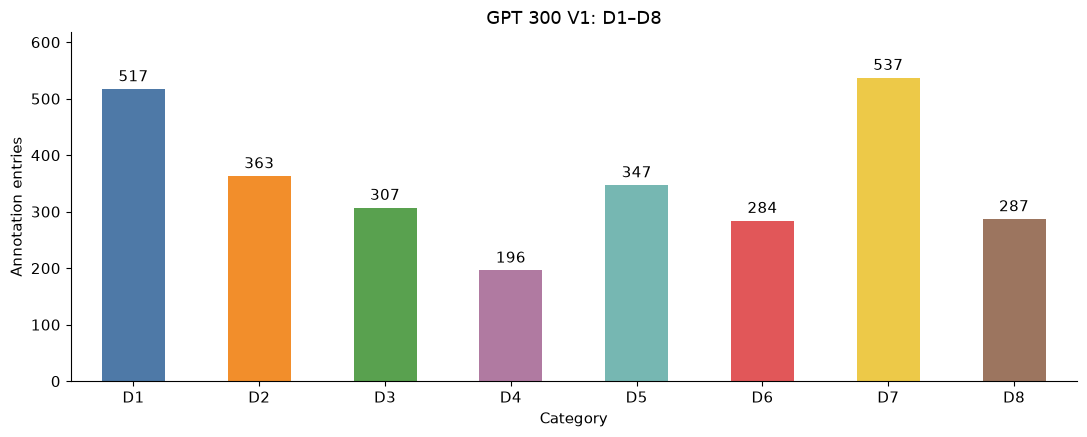

In [56]:
show_overall_distribution(gpt_v1, "GPT 300 V1", "category")


GPT 300 V1: Explicit and contextual visibility — overall counts and percentages


,Annotation entries,Distribution (%)
visibility,,
Explicit,886,31.22
Contextual,1952,68.78


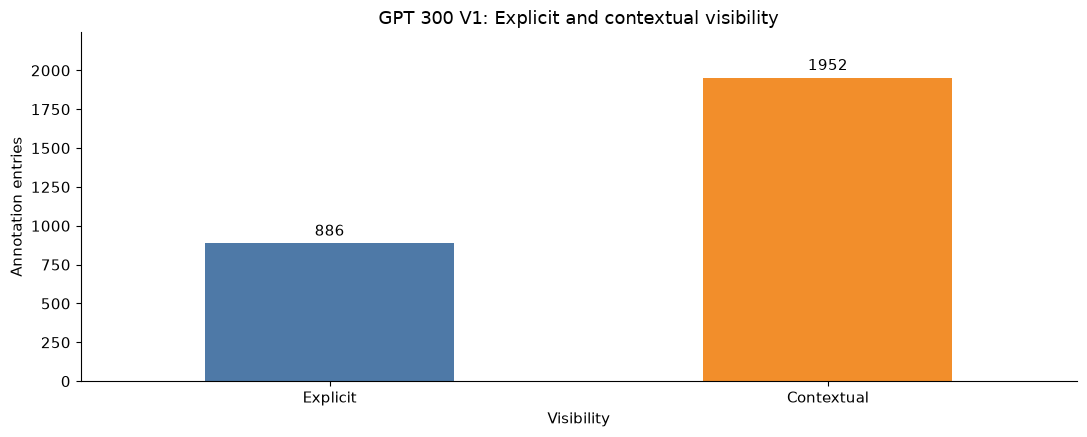

In [57]:
show_overall_distribution(gpt_v1, "GPT 300 V1", "visibility")


### 1.2 D1–D8 by trajectory model

The count table is followed by the within-model percentage distribution and its chart.


GPT 300 V1: D1–D8 by model — annotation counts


category,D1,D2,D3,D4,D5,D6,D7,D8
model,,,,,,,,
claude-fable-5,45,35,33,22,33,22,51,31
claude-opus-4-7,54,38,34,28,36,24,61,31
claude-opus-4-8,38,25,18,16,21,13,35,18
claude-sonnet-5,40,29,20,18,25,14,32,18
gemini-3-pro-preview,22,15,14,10,15,14,23,16
gemini-3.1-pro-preview,81,59,44,24,47,46,82,49
glm-5.1,25,15,15,8,19,13,22,13
gpt-5.5,52,43,50,20,41,26,61,36
gpt-5.6-luna,42,22,19,12,33,21,45,18


GPT 300 V1: D1–D8 by model — within-row distribution (%)


category,D1 (%),D2 (%),D3 (%),D4 (%),D5 (%),D6 (%),D7 (%),D8 (%)
model,,,,,,,,
claude-fable-5,16.54,12.87,12.13,8.09,12.13,8.09,18.75,11.40
claude-opus-4-7,17.65,12.42,11.11,9.15,11.76,7.84,19.93,10.13
claude-opus-4-8,20.65,13.59,9.78,8.70,11.41,7.07,19.02,9.78
claude-sonnet-5,20.41,14.80,10.20,9.18,12.76,7.14,16.33,9.18
gemini-3-pro-preview,17.05,11.63,10.85,7.75,11.63,10.85,17.83,12.40
gemini-3.1-pro-preview,18.75,13.66,10.19,5.56,10.88,10.65,18.98,11.34
glm-5.1,19.23,11.54,11.54,6.15,14.62,10.00,16.92,10.00
gpt-5.5,15.81,13.07,15.20,6.08,12.46,7.90,18.54,10.94
gpt-5.6-luna,19.81,10.38,8.96,5.66,15.57,9.91,21.23,8.49


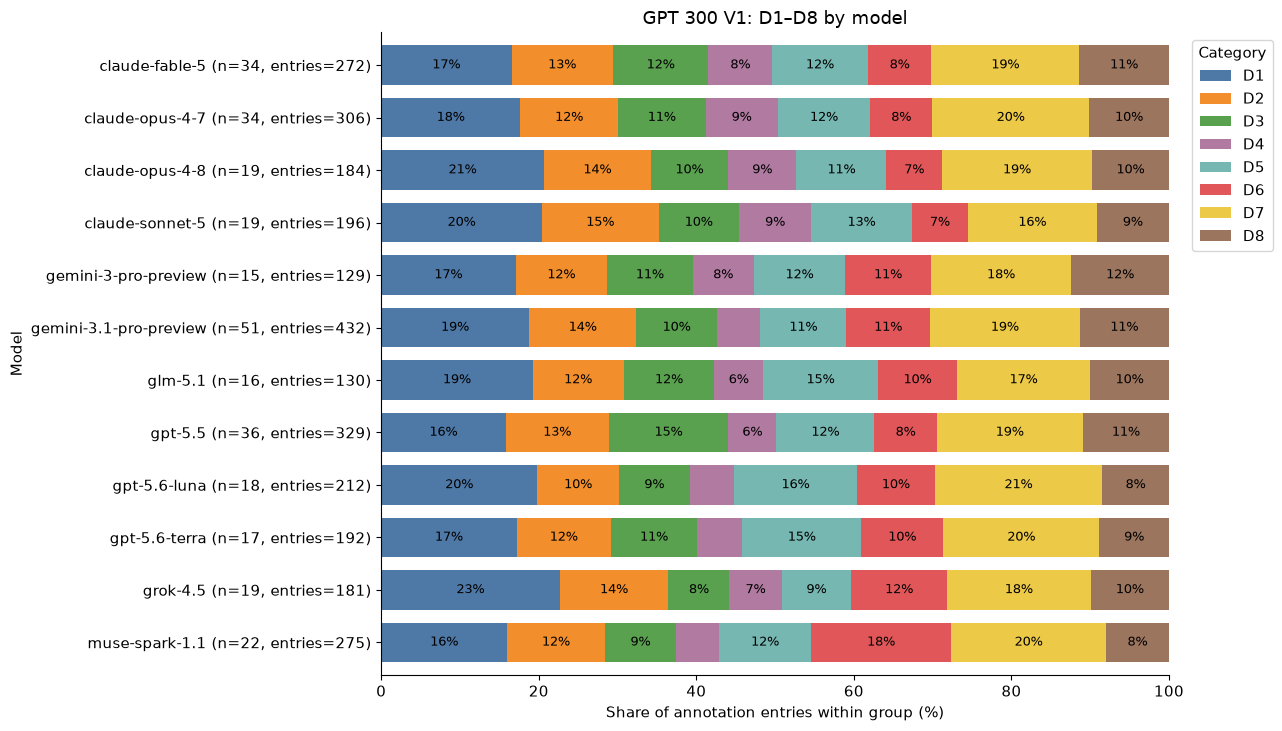

In [58]:
show_group_distribution(gpt_v1, "GPT 300 V1", "model", "category")


### 1.3 D1–D8 by harness

The count table is followed by the within-harness percentage distribution and its chart.


GPT 300 V1: D1–D8 by harness — annotation counts


category,D1,D2,D3,D4,D5,D6,D7,D8
harness,,,,,,,,
claude-code,156,107,85,62,95,57,138,77
codex,101,62,61,31,78,55,111,50
cursor-cli,41,25,14,12,16,22,33,18
gemini-cli,58,45,30,18,29,28,56,32
mini-swe-agent,44,34,25,15,32,49,54,22
terminus-2,117,90,92,58,97,73,145,88


GPT 300 V1: D1–D8 by harness — within-row distribution (%)


category,D1 (%),D2 (%),D3 (%),D4 (%),D5 (%),D6 (%),D7 (%),D8 (%)
harness,,,,,,,,
claude-code,20.08,13.77,10.94,7.98,12.23,7.34,17.76,9.91
codex,18.40,11.29,11.11,5.65,14.21,10.02,20.22,9.11
cursor-cli,22.65,13.81,7.73,6.63,8.84,12.15,18.23,9.94
gemini-cli,19.59,15.20,10.14,6.08,9.80,9.46,18.92,10.81
mini-swe-agent,16.00,12.36,9.09,5.45,11.64,17.82,19.64,8.00
terminus-2,15.39,11.84,12.11,7.63,12.76,9.61,19.08,11.58


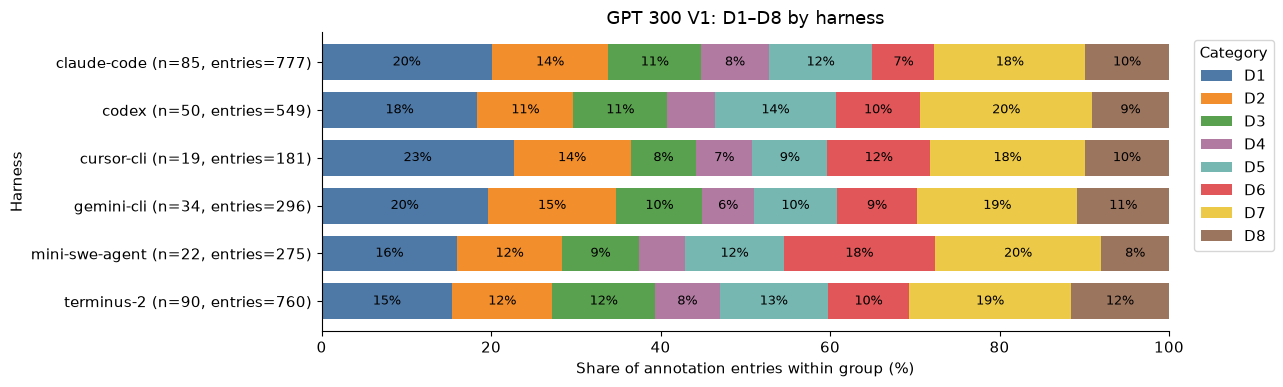

In [59]:
show_group_distribution(gpt_v1, "GPT 300 V1", "harness", "category")


### 1.4 Explicit and contextual visibility by trajectory model

The count table is followed by the within-model percentage distribution and its chart.


GPT 300 V1: Explicit/Contextual by model — annotation counts


visibility,Explicit,Contextual
model,,
claude-fable-5,87,185
claude-opus-4-7,113,193
claude-opus-4-8,76,108
claude-sonnet-5,43,153
gemini-3-pro-preview,6,123
gemini-3.1-pro-preview,146,286
glm-5.1,83,47
gpt-5.5,114,215
gpt-5.6-luna,36,176


GPT 300 V1: Explicit/Contextual by model — within-row distribution (%)


visibility,Explicit (%),Contextual (%)
model,,
claude-fable-5,31.99,68.01
claude-opus-4-7,36.93,63.07
claude-opus-4-8,41.30,58.70
claude-sonnet-5,21.94,78.06
gemini-3-pro-preview,4.65,95.35
gemini-3.1-pro-preview,33.80,66.20
glm-5.1,63.85,36.15
gpt-5.5,34.65,65.35
gpt-5.6-luna,16.98,83.02


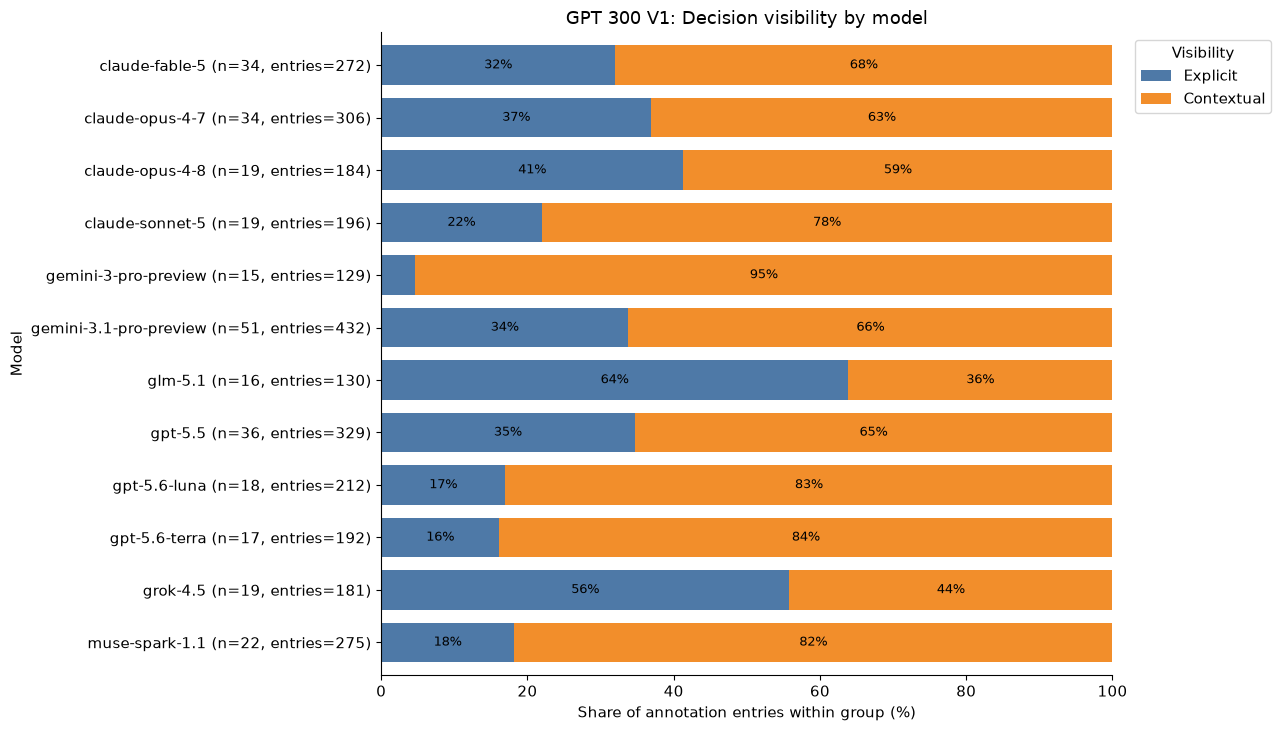

In [60]:
show_group_distribution(gpt_v1, "GPT 300 V1", "model", "visibility")


### 1.5 Explicit and contextual visibility by harness

The count table is followed by the within-harness percentage distribution and its chart.


GPT 300 V1: Explicit/Contextual by harness — annotation counts


visibility,Explicit,Contextual
harness,,
claude-code,362,415
codex,159,390
cursor-cli,101,80
gemini-cli,144,152
mini-swe-agent,50,225
terminus-2,70,690


GPT 300 V1: Explicit/Contextual by harness — within-row distribution (%)


visibility,Explicit (%),Contextual (%)
harness,,
claude-code,46.59,53.41
codex,28.96,71.04
cursor-cli,55.80,44.20
gemini-cli,48.65,51.35
mini-swe-agent,18.18,81.82
terminus-2,9.21,90.79


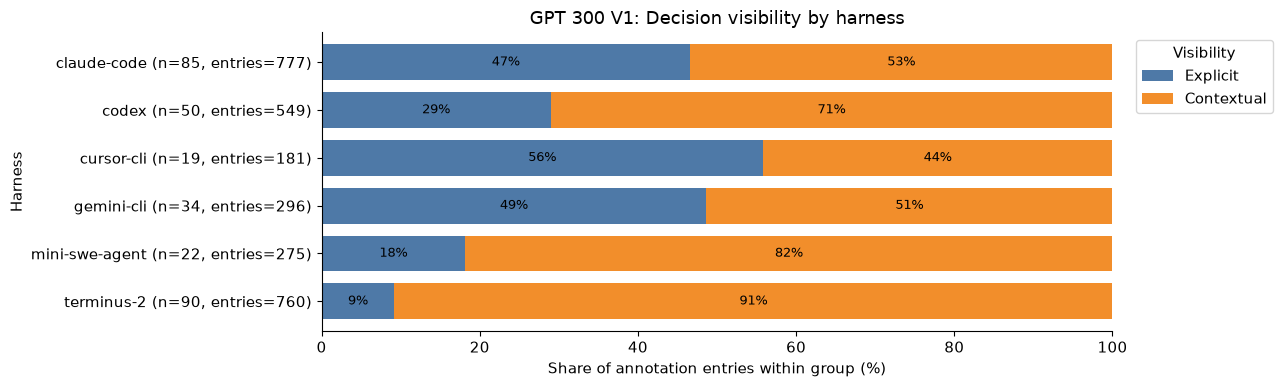

In [61]:
show_group_distribution(gpt_v1, "GPT 300 V1", "harness", "visibility")


### 1.6 Model × harness combinations

Coverage, category counts and percentages, and visibility counts and percentages for each combination.


In [62]:
show_combinations(gpt_v1, "GPT 300 V1")


GPT 300 V1: model × harness coverage


trajectories  tasks  \
harness        model                                         
claude-code    claude-fable-5                    14     13   
               claude-opus-4-7                   17     15   
               claude-opus-4-8                   19     15   
               claude-sonnet-5                   19     15   
               glm-5.1                           16     15   
codex          gpt-5.5                           15     15   
               gpt-5.6-luna                      18     15   
               gpt-5.6-terra                     17     15   
cursor-cli     grok-4.5                          19     15   
gemini-cli     gemini-3.1-pro-preview            34     15   
mini-swe-agent muse-spark-1.1                    22     15   
terminus-2     claude-fable-5                    20     15   
               claude-opus-4-7                   17     15   
               gemini-3-pro-preview              15     15   
               gemini-3.1-pro-preview            17     15   
               gpt-5.5                           21     15   

                                       trajectories_with_entries  \
harness        model                                               
claude-code    claude-fable-5                                 14   
               claude-opus-4-7                                17   
               claude-opus-4-8                                19   
               claude-sonnet-5                                19   
               glm-5.1                                        16   
codex          gpt-5.5                                        15   
               gpt-5.6-luna                                   18   
               gpt-5.6-terra                                  17   
cursor-cli     grok-4.5                                       19   
gemini-cli     gemini-3.1-pro-preview                         34   
mini-swe-agent muse-spark-1.1                                 22   
terminus-2     claude-fable-5                                 20   
               claude-opus-4-7                                17   
               gemini-3-pro-preview                           15   
               gemini-3.1-pro-preview                         17   
               gpt-5.5                                        21   

                                       annotation_entries  \
harness        model                                        
claude-code    claude-fable-5                         123   
               claude-opus-4-7                        144   
               claude-opus-4-8                        184   
               claude-sonnet-5                        196   
               glm-5.1                                130   
codex          gpt-5.5                                145   
               gpt-5.6-luna                           212   
               gpt-5.6-terra                          192   
cursor-cli     grok-4.5                               181   
gemini-cli     gemini-3.1-pro-preview                 296   
mini-swe-agent muse-spark-1.1                         275   
terminus-2     claude-fable-5                         149   
               claude-opus-4-7                        162   
               gemini-3-pro-preview                   129   
               gemini-3.1-pro-preview                 136   
               gpt-5.5                                184   

                                       mean_entries_per_trajectory  \
harness        model                                                 
claude-code    claude-fable-5                                 8.79   
               claude-opus-4-7                                8.47   
               claude-opus-4-8                                9.68   
               claude-sonnet-5                               10.32   
               glm-5.1                                        8.12   
codex          gpt-5.5                                        9.67   
               gpt-5.6-luna           

GPT 300 V1: D1–D8 by harness × model — annotation counts


category                               D1  D2  D3  D4  D5  D6  D7  D8
harness        model                                                 
claude-code    claude-fable-5          25  17  14  10  15   9  21  12
               claude-opus-4-7         28  21  18  10  15   8  28  16
               claude-opus-4-8         38  25  18  16  21  13  35  18
               claude-sonnet-5         40  29  20  18  25  14  32  18
               glm-5.1                 25  15  15   8  19  13  22  13
codex          gpt-5.5                 26  17  21   8  16  14  28  15
               gpt-5.6-luna            42  22  19  12  33  21  45  18
               gpt-5.6-terra           33  23  21  11  29  20  38  17
cursor-cli     grok-4.5                41  25  14  12  16  22  33  18
gemini-cli     gemini-3.1-pro-preview  58  45  30  18  29  28  56  32
mini-swe-agent muse-spark-1.1          44  34  25  15  32  49  54  22
terminus-2     claude-fable-5          20  18  19  12  18  13  30  19
               claude-opus-4-7         26  17  16  18  21  16  33  15
               gemini-3-pro-preview    22  15  14  10  15  14  23  16
               gemini-3.1-pro-preview  23  14  14   6  18  18  26  17
               gpt-5.5                 26  26  29  12  25  12  33  21

GPT 300 V1: D1–D8 by harness × model — within-row distribution (%)


category                               D1 (%)  D2 (%)  D3 (%)  D4 (%)  D5 (%)  \
harness        model                                                            
claude-code    claude-fable-5           20.33   13.82   11.38    8.13   12.20   
               claude-opus-4-7          19.44   14.58   12.50    6.94   10.42   
               claude-opus-4-8          20.65   13.59    9.78    8.70   11.41   
               claude-sonnet-5          20.41   14.80   10.20    9.18   12.76   
               glm-5.1                  19.23   11.54   11.54    6.15   14.62   
codex          gpt-5.5                  17.93   11.72   14.48    5.52   11.03   
               gpt-5.6-luna             19.81   10.38    8.96    5.66   15.57   
               gpt-5.6-terra            17.19   11.98   10.94    5.73   15.10   
cursor-cli     grok-4.5                 22.65   13.81    7.73    6.63    8.84   
gemini-cli     gemini-3.1-pro-preview   19.59   15.20   10.14    6.08    9.80   
mini-swe-agent muse-spark-1.1           16.00   12.36    9.09    5.45   11.64   
terminus-2     claude-fable-5           13.42   12.08   12.75    8.05   12.08   
               claude-opus-4-7          16.05   10.49    9.88   11.11   12.96   
               gemini-3-pro-preview     17.05   11.63   10.85    7.75   11.63   
               gemini-3.1-pro-preview   16.91   10.29   10.29    4.41   13.24   
               gpt-5.5                  14.13   14.13   15.76    6.52   13.59   

category                               D6 (%)  D7 (%)  D8 (%)  
harness        model                                           
claude-code    claude-fable-5            7.32   17.07    9.76  
               claude-opus-4-7           5.56   19.44   11.11  
               claude-opus-4-8           7.07   19.02    9.78  
               claude-sonnet-5           7.14   16.33    9.18  
               glm-5.1                  10.00   16.92   10.00  
codex          gpt-5.5                   9.66   19.31   10.34  
               gpt-5.6-luna              9.91   21.23    8.49  
               gpt-5.6-terra            10.42   19.79    8.85  
cursor-cli     grok-4.5                 12.15   18.23    9.94  
gemini-cli     gemini-3.1-pro-preview    9.46   18.92   10.81  
mini-swe-agent muse-spark-1.1           17.82   19.64    8.00  
terminus-2     claude-fable-5            8.72   20.13   12.75  
               claude-opus-4-7           9.88   20.37    9.26  
               gemini-3-pro-preview     10.85   17.83   12.40  
               gemini-3.1-pro-preview   13.24   19.12   12.50  
               gpt-5.5                   6.52   17.93   11.41

GPT 300 V1: Explicit/Contextual by harness × model — annotation counts


visibility                             Explicit  Contextual
harness        model                                       
claude-code    claude-fable-5                71          52
               claude-opus-4-7               89          55
               claude-opus-4-8               76         108
               claude-sonnet-5               43         153
               glm-5.1                       83          47
codex          gpt-5.5                       92          53
               gpt-5.6-luna                  36         176
               gpt-5.6-terra                 31         161
cursor-cli     grok-4.5                     101          80
gemini-cli     gemini-3.1-pro-preview       144         152
mini-swe-agent muse-spark-1.1                50         225
terminus-2     claude-fable-5                16         133
               claude-opus-4-7               24         138
               gemini-3-pro-preview           6         123
               gemini-3.1-pro-preview         2         134
               gpt-5.5                       22         162

GPT 300 V1: Explicit/Contextual by harness × model — within-row distribution (%)


visibility                             Explicit (%)  Contextual (%)
harness        model                                               
claude-code    claude-fable-5                 57.72           42.28
               claude-opus-4-7                61.81           38.19
               claude-opus-4-8                41.30           58.70
               claude-sonnet-5                21.94           78.06
               glm-5.1                        63.85           36.15
codex          gpt-5.5                        63.45           36.55
               gpt-5.6-luna                   16.98           83.02
               gpt-5.6-terra                  16.15           83.85
cursor-cli     grok-4.5                       55.80           44.20
gemini-cli     gemini-3.1-pro-preview         48.65           51.35
mini-swe-agent muse-spark-1.1                 18.18           81.82
terminus-2     claude-fable-5                 10.74           89.26
               claude-opus-4-7                14.81           85.19
               gemini-3-pro-preview            4.65           95.35
               gemini-3.1-pro-preview          1.47           98.53
               gpt-5.5                        11.96           88.04

### 1.7 Findings and interpretation

The summary reports the most frequent category and visibility composition overall and per model and harness. These distributions describe the recorded annotations; they do not establish causal effects of a model or harness.


In [63]:
show_findings(gpt_v1, "GPT 300 V1")


GPT 300 V1: 300 trajectories across 15 tasks; 2,838 category annotation entries.
Most frequent category: D7 — Verification choice (537 entries; 18.92%).
Visibility denominator: 2,838 valid entries.
Visibility: 31.22% Explicit; 68.78% Contextual.
GPT 300 V1: summary by model


,trajectories,tasks,annotation_entries,mean_entries_per_trajectory,median_entries_per_trajectory,most_frequent_category,most_frequent_category_pct,valid_visibility_entries,explicit_pct,contextual_pct
model,,,,,,,,,,
claude-fable-5,34,15,272,8.00,7.0,D7,18.75,272,31.99,68.01
claude-opus-4-7,34,15,306,9.00,7.5,D7,19.93,306,36.93,63.07
claude-opus-4-8,19,15,184,9.68,10.0,D1,20.65,184,41.30,58.70
claude-sonnet-5,19,15,196,10.32,8.0,D1,20.41,196,21.94,78.06
gemini-3-pro-preview,15,15,129,8.60,7.0,D7,17.83,129,4.65,95.35
gemini-3.1-pro-preview,51,15,432,8.47,7.0,D7,18.98,432,33.80,66.20
glm-5.1,16,15,130,8.12,7.0,D1,19.23,130,63.85,36.15
gpt-5.5,36,15,329,9.14,9.0,D7,18.54,329,34.65,65.35
gpt-5.6-luna,18,15,212,11.78,11.0,D7,21.23,212,16.98,83.02


GPT 300 V1: summary by harness


,trajectories,tasks,annotation_entries,mean_entries_per_trajectory,median_entries_per_trajectory,most_frequent_category,most_frequent_category_pct,valid_visibility_entries,explicit_pct,contextual_pct
harness,,,,,,,,,,
claude-code,85,15,777,9.14,8.0,D1,20.08,777,46.59,53.41
codex,50,15,549,10.98,10.0,D7,20.22,549,28.96,71.04
cursor-cli,19,15,181,9.53,7.0,D1,22.65,181,55.80,44.20
gemini-cli,34,15,296,8.71,7.0,D1,19.59,296,48.65,51.35
mini-swe-agent,22,15,275,12.50,11.5,D7,19.64,275,18.18,81.82
terminus-2,90,15,760,8.44,7.0,D7,19.08,760,9.21,90.79


## 2. GPT 300 Analysis — V2

The final V2 workbook contains the full 300-trajectory sample. The source rows are checked against V1, and the same tables and charts are applied to V2 annotations.


In [64]:
gpt_v2 = read_full_sample(V2_WORKBOOK_PATH)
check_same_sample(gpt_v1, gpt_v2, "GPT 300 V2")
show_annotation_checks(gpt_v2, "GPT 300 V2")


GPT 300 V2 and V1 cover the same 300 trajectories and recorded steps.
GPT 300 V2: 0 category entries excluded from visibility distributions.
GPT 300 V2: no annotation formatting issues found.


### 2.1 Dataset coverage and overall distributions


In [65]:
show_overview(gpt_v2, "GPT 300 V2")


,GPT 300 V2
Tasks,15
Trajectories,300
Trajectory models,12
Harnesses,6
Recorded step rows,5196
Step rows with taxonomy annotations,1724
Category annotation entries,2496
Trajectories with no annotation entries,0
Entries included in visibility analysis,2496


GPT 300 V2: coverage by task


,trajectories,tasks,trajectories_with_entries,annotation_entries,mean_entries_per_trajectory,median_entries_per_trajectory
task,,,,,,
cancel-async-tasks,20,1,20,142,7.10,7.0
count-dataset-tokens,20,1,20,155,7.75,8.0
fix-git,20,1,20,106,5.30,5.0
git-leak-recovery,20,1,20,100,5.00,5.0
headless-terminal,20,1,20,243,12.15,11.0
kv-store-grpc,20,1,20,186,9.30,8.5
llm-inference-batching-schedule,20,1,20,222,11.10,10.5
modernize-scientific-stack,20,1,20,135,6.75,6.5
mteb-retrieve,20,1,20,117,5.85,6.0


GPT 300 V2: coverage by model


,trajectories,tasks,trajectories_with_entries,annotation_entries,mean_entries_per_trajectory,median_entries_per_trajectory
model,,,,,,
claude-fable-5,34,15,34,241,7.09,6.0
claude-opus-4-7,34,15,34,295,8.68,7.5
claude-opus-4-8,19,15,19,167,8.79,8.0
claude-sonnet-5,19,15,19,168,8.84,8.0
gemini-3-pro-preview,15,15,15,106,7.07,6.0
gemini-3.1-pro-preview,51,15,51,380,7.45,7.0
glm-5.1,16,15,16,117,7.31,6.5
gpt-5.5,36,15,36,305,8.47,7.5
gpt-5.6-luna,18,15,18,164,9.11,7.5


GPT 300 V2: coverage by harness


,trajectories,tasks,trajectories_with_entries,annotation_entries,mean_entries_per_trajectory,median_entries_per_trajectory
harness,,,,,,
claude-code,85,15,85,701,8.25,8.0
codex,50,15,50,458,9.16,8.0
cursor-cli,19,15,19,156,8.21,7.0
gemini-cli,34,15,34,259,7.62,7.0
mini-swe-agent,22,15,22,232,10.55,11.0
terminus-2,90,15,90,690,7.67,7.0


GPT 300 V2: D1–D8 — overall counts and percentages


,Annotation entries,Distribution (%)
category,,
D1,374,14.98
D2,331,13.26
D3,180,7.21
D4,227,9.09
D5,412,16.51
D6,167,6.69
D7,521,20.87
D8,284,11.38


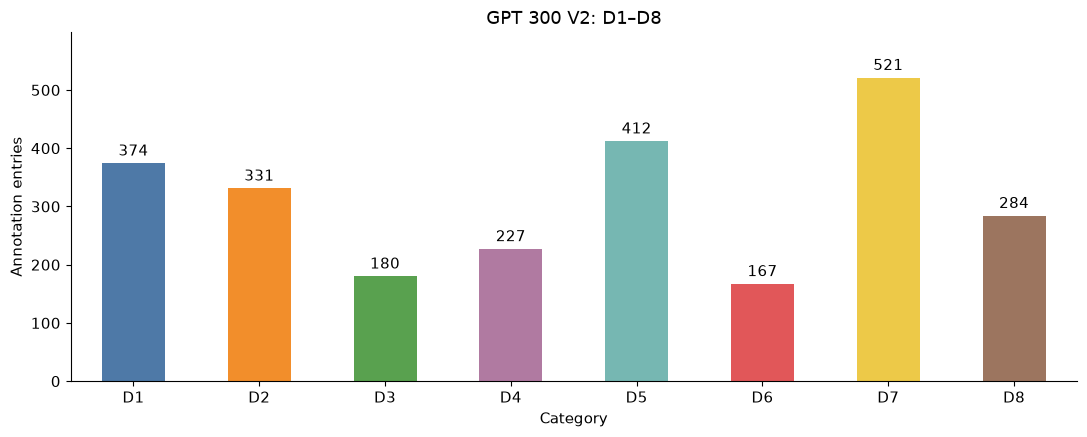

In [66]:
show_overall_distribution(gpt_v2, "GPT 300 V2", "category")


GPT 300 V2: Explicit and contextual visibility — overall counts and percentages


,Annotation entries,Distribution (%)
visibility,,
Explicit,924,37.02
Contextual,1572,62.98


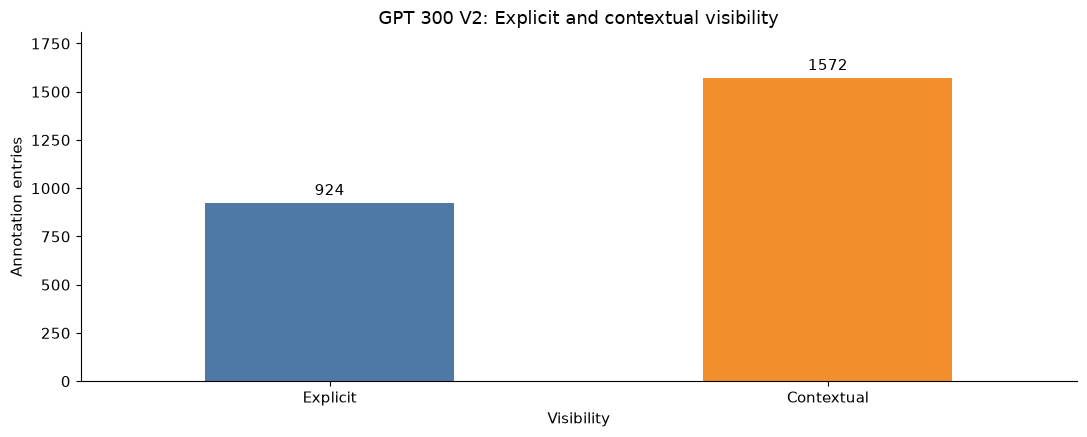

In [67]:
show_overall_distribution(gpt_v2, "GPT 300 V2", "visibility")


### 2.2 D1–D8 by trajectory model

The count table is followed by the within-model percentage distribution and its chart.


GPT 300 V2: D1–D8 by model — annotation counts


category,D1,D2,D3,D4,D5,D6,D7,D8
model,,,,,,,,
claude-fable-5,36,28,23,25,41,9,48,31
claude-opus-4-7,45,37,22,29,47,15,69,31
claude-opus-4-8,24,22,13,20,30,8,32,18
claude-sonnet-5,28,23,12,16,28,8,35,18
gemini-3-pro-preview,17,14,6,10,14,10,20,15
gemini-3.1-pro-preview,61,57,23,34,56,30,71,48
glm-5.1,17,13,11,10,21,9,23,13
gpt-5.5,41,43,22,27,57,20,59,36
gpt-5.6-luna,18,21,11,13,30,10,43,18


GPT 300 V2: D1–D8 by model — within-row distribution (%)


category,D1 (%),D2 (%),D3 (%),D4 (%),D5 (%),D6 (%),D7 (%),D8 (%)
model,,,,,,,,
claude-fable-5,14.94,11.62,9.54,10.37,17.01,3.73,19.92,12.86
claude-opus-4-7,15.25,12.54,7.46,9.83,15.93,5.08,23.39,10.51
claude-opus-4-8,14.37,13.17,7.78,11.98,17.96,4.79,19.16,10.78
claude-sonnet-5,16.67,13.69,7.14,9.52,16.67,4.76,20.83,10.71
gemini-3-pro-preview,16.04,13.21,5.66,9.43,13.21,9.43,18.87,14.15
gemini-3.1-pro-preview,16.05,15.00,6.05,8.95,14.74,7.89,18.68,12.63
glm-5.1,14.53,11.11,9.40,8.55,17.95,7.69,19.66,11.11
gpt-5.5,13.44,14.10,7.21,8.85,18.69,6.56,19.34,11.80
gpt-5.6-luna,10.98,12.80,6.71,7.93,18.29,6.10,26.22,10.98


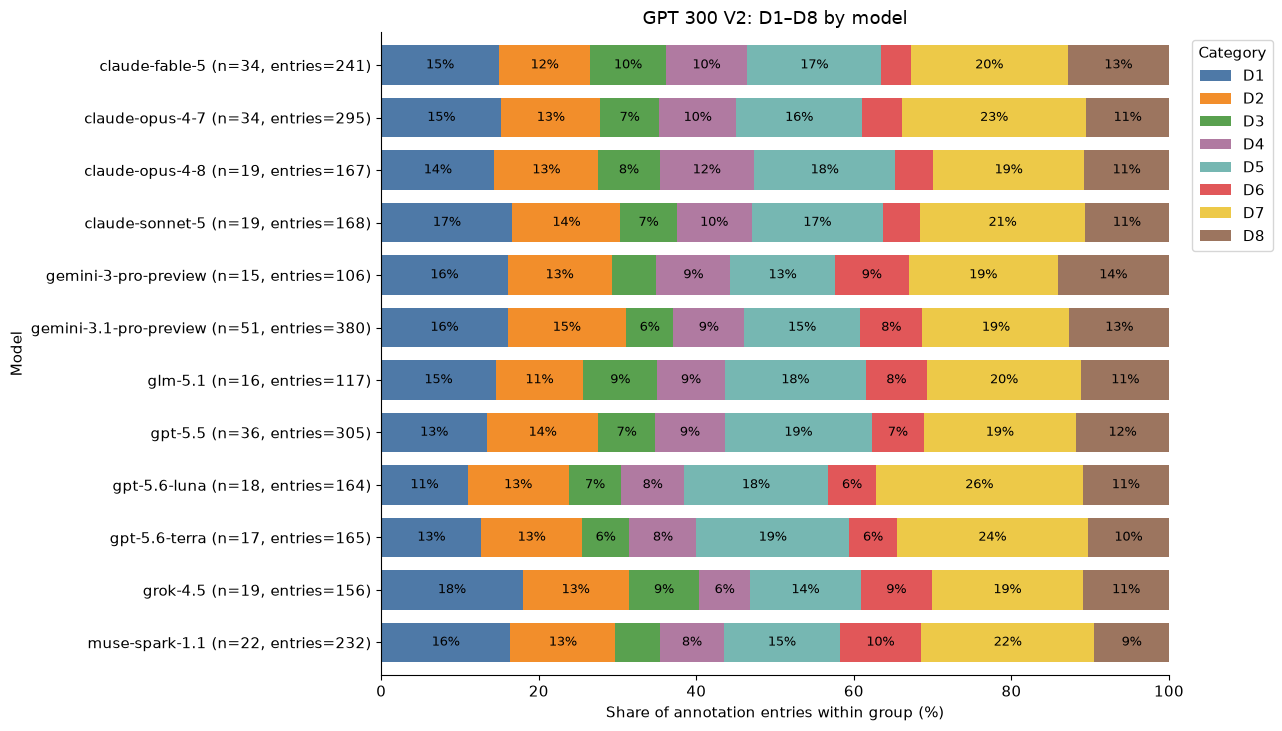

In [68]:
show_group_distribution(gpt_v2, "GPT 300 V2", "model", "category")


### 2.3 D1–D8 by harness

The count table is followed by the within-harness percentage distribution and its chart.


GPT 300 V2: D1–D8 by harness — annotation counts


category,D1,D2,D3,D4,D5,D6,D7,D8
harness,,,,,,,,
claude-code,109,89,54,75,122,36,139,77
codex,60,59,31,38,81,30,109,50
cursor-cli,28,21,14,10,22,14,30,17
gemini-cli,46,39,16,25,35,22,45,31
mini-swe-agent,38,31,13,19,34,24,51,22
terminus-2,93,92,52,60,118,41,147,87


GPT 300 V2: D1–D8 by harness — within-row distribution (%)


category,D1 (%),D2 (%),D3 (%),D4 (%),D5 (%),D6 (%),D7 (%),D8 (%)
harness,,,,,,,,
claude-code,15.55,12.70,7.70,10.70,17.40,5.14,19.83,10.98
codex,13.10,12.88,6.77,8.30,17.69,6.55,23.80,10.92
cursor-cli,17.95,13.46,8.97,6.41,14.10,8.97,19.23,10.90
gemini-cli,17.76,15.06,6.18,9.65,13.51,8.49,17.37,11.97
mini-swe-agent,16.38,13.36,5.60,8.19,14.66,10.34,21.98,9.48
terminus-2,13.48,13.33,7.54,8.70,17.10,5.94,21.30,12.61


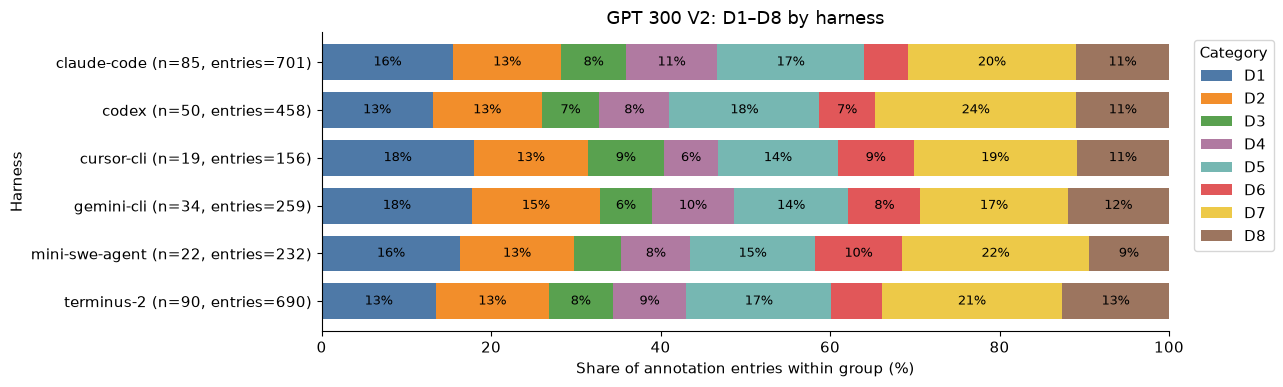

In [69]:
show_group_distribution(gpt_v2, "GPT 300 V2", "harness", "category")


### 2.4 Explicit and contextual visibility by trajectory model

The count table is followed by the within-model percentage distribution and its chart.


GPT 300 V2: Explicit/Contextual by model — annotation counts


visibility,Explicit,Contextual
model,,
claude-fable-5,83,158
claude-opus-4-7,104,191
claude-opus-4-8,111,56
claude-sonnet-5,88,80
gemini-3-pro-preview,6,100
gemini-3.1-pro-preview,155,225
glm-5.1,84,33
gpt-5.5,96,209
gpt-5.6-luna,51,113


GPT 300 V2: Explicit/Contextual by model — within-row distribution (%)


visibility,Explicit (%),Contextual (%)
model,,
claude-fable-5,34.44,65.56
claude-opus-4-7,35.25,64.75
claude-opus-4-8,66.47,33.53
claude-sonnet-5,52.38,47.62
gemini-3-pro-preview,5.66,94.34
gemini-3.1-pro-preview,40.79,59.21
glm-5.1,71.79,28.21
gpt-5.5,31.48,68.52
gpt-5.6-luna,31.10,68.90


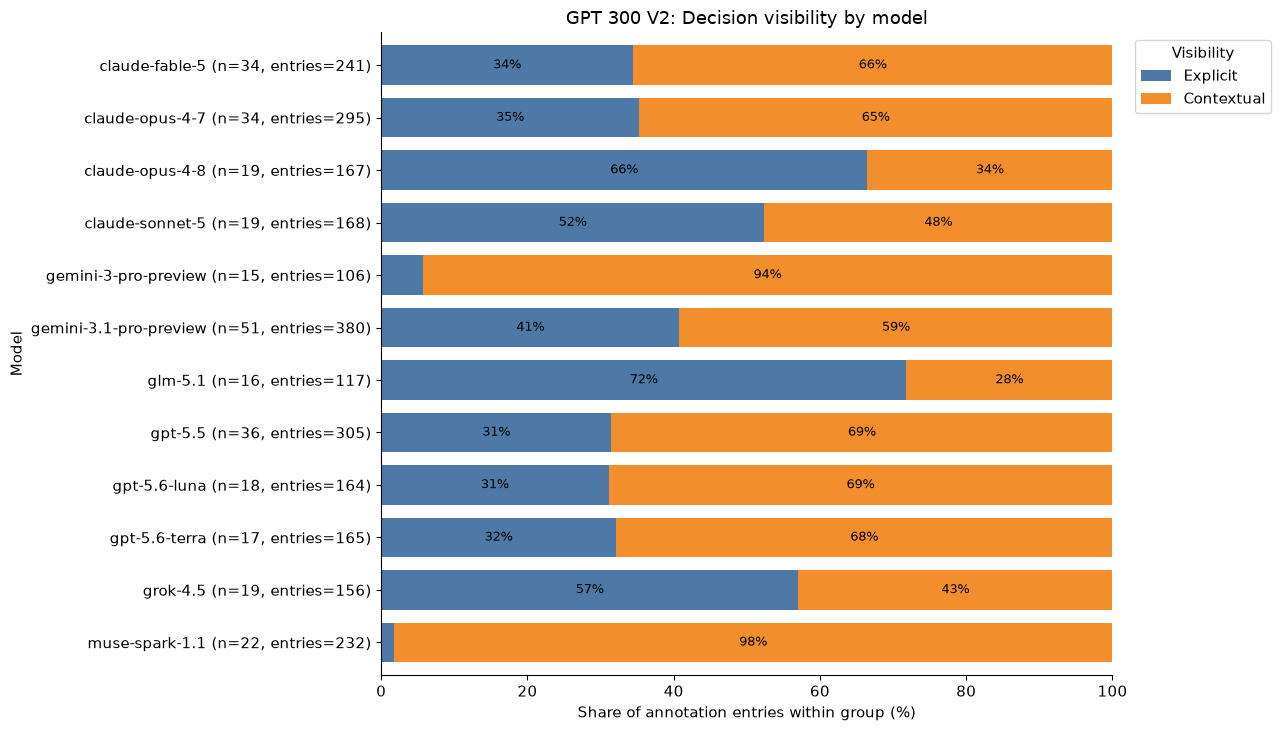

In [70]:
show_group_distribution(gpt_v2, "GPT 300 V2", "model", "visibility")


### 2.5 Explicit and contextual visibility by harness

The count table is followed by the within-harness percentage distribution and its chart.


GPT 300 V2: Explicit/Contextual by harness — annotation counts


visibility,Explicit,Contextual
harness,,
claude-code,466,235
codex,194,264
cursor-cli,89,67
gemini-cli,155,104
mini-swe-agent,4,228
terminus-2,16,674


GPT 300 V2: Explicit/Contextual by harness — within-row distribution (%)


visibility,Explicit (%),Contextual (%)
harness,,
claude-code,66.48,33.52
codex,42.36,57.64
cursor-cli,57.05,42.95
gemini-cli,59.85,40.15
mini-swe-agent,1.72,98.28
terminus-2,2.32,97.68


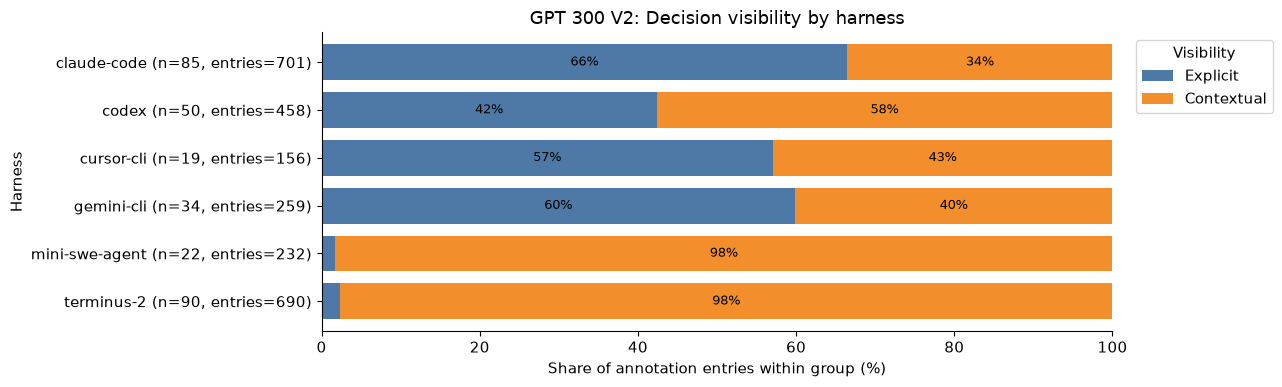

In [71]:
show_group_distribution(gpt_v2, "GPT 300 V2", "harness", "visibility")


### 2.6 Model × harness combinations

Coverage, category counts and percentages, and visibility counts and percentages for each combination.


In [72]:
show_combinations(gpt_v2, "GPT 300 V2")


GPT 300 V2: model × harness coverage


trajectories  tasks  \
harness        model                                         
claude-code    claude-fable-5                    14     13   
               claude-opus-4-7                   17     15   
               claude-opus-4-8                   19     15   
               claude-sonnet-5                   19     15   
               glm-5.1                           16     15   
codex          gpt-5.5                           15     15   
               gpt-5.6-luna                      18     15   
               gpt-5.6-terra                     17     15   
cursor-cli     grok-4.5                          19     15   
gemini-cli     gemini-3.1-pro-preview            34     15   
mini-swe-agent muse-spark-1.1                    22     15   
terminus-2     claude-fable-5                    20     15   
               claude-opus-4-7                   17     15   
               gemini-3-pro-preview              15     15   
               gemini-3.1-pro-preview            17     15   
               gpt-5.5                           21     15   

                                       trajectories_with_entries  \
harness        model                                               
claude-code    claude-fable-5                                 14   
               claude-opus-4-7                                17   
               claude-opus-4-8                                19   
               claude-sonnet-5                                19   
               glm-5.1                                        16   
codex          gpt-5.5                                        15   
               gpt-5.6-luna                                   18   
               gpt-5.6-terra                                  17   
cursor-cli     grok-4.5                                       19   
gemini-cli     gemini-3.1-pro-preview                         34   
mini-swe-agent muse-spark-1.1                                 22   
terminus-2     claude-fable-5                                 20   
               claude-opus-4-7                                17   
               gemini-3-pro-preview                           15   
               gemini-3.1-pro-preview                         17   
               gpt-5.5                                        21   

                                       annotation_entries  \
harness        model                                        
claude-code    claude-fable-5                         106   
               claude-opus-4-7                        143   
               claude-opus-4-8                        167   
               claude-sonnet-5                        168   
               glm-5.1                                117   
codex          gpt-5.5                                129   
               gpt-5.6-luna                           164   
               gpt-5.6-terra                          165   
cursor-cli     grok-4.5                               156   
gemini-cli     gemini-3.1-pro-preview                 259   
mini-swe-agent muse-spark-1.1                         232   
terminus-2     claude-fable-5                         135   
               claude-opus-4-7                        152   
               gemini-3-pro-preview                   106   
               gemini-3.1-pro-preview                 121   
               gpt-5.5                                176   

                                       mean_entries_per_trajectory  \
harness        model                                                 
claude-code    claude-fable-5                                 7.57   
               claude-opus-4-7                                8.41   
               claude-opus-4-8                                8.79   
               claude-sonnet-5                                8.84   
               glm-5.1                                        7.31   
codex          gpt-5.5                                        8.60   
               gpt-5.6-luna           

GPT 300 V2: D1–D8 by harness × model — annotation counts


category                               D1  D2  D3  D4  D5  D6  D7  D8
harness        model                                                 
claude-code    claude-fable-5          19  12   8  12  20   3  20  12
               claude-opus-4-7         21  19  10  17  23   8  29  16
               claude-opus-4-8         24  22  13  20  30   8  32  18
               claude-sonnet-5         28  23  12  16  28   8  35  18
               glm-5.1                 17  13  11  10  21   9  23  13
codex          gpt-5.5                 21  17  10  11  19  10  26  15
               gpt-5.6-luna            18  21  11  13  30  10  43  18
               gpt-5.6-terra           21  21  10  14  32  10  40  17
cursor-cli     grok-4.5                28  21  14  10  22  14  30  17
gemini-cli     gemini-3.1-pro-preview  46  39  16  25  35  22  45  31
mini-swe-agent muse-spark-1.1          38  31  13  19  34  24  51  22
terminus-2     claude-fable-5          17  16  15  13  21   6  28  19
               claude-opus-4-7         24  18  12  12  24   7  40  15
               gemini-3-pro-preview    17  14   6  10  14  10  20  15
               gemini-3.1-pro-preview  15  18   7   9  21   8  26  17
               gpt-5.5                 20  26  12  16  38  10  33  21

GPT 300 V2: D1–D8 by harness × model — within-row distribution (%)


category                               D1 (%)  D2 (%)  D3 (%)  D4 (%)  D5 (%)  \
harness        model                                                            
claude-code    claude-fable-5           17.92   11.32    7.55   11.32   18.87   
               claude-opus-4-7          14.69   13.29    6.99   11.89   16.08   
               claude-opus-4-8          14.37   13.17    7.78   11.98   17.96   
               claude-sonnet-5          16.67   13.69    7.14    9.52   16.67   
               glm-5.1                  14.53   11.11    9.40    8.55   17.95   
codex          gpt-5.5                  16.28   13.18    7.75    8.53   14.73   
               gpt-5.6-luna             10.98   12.80    6.71    7.93   18.29   
               gpt-5.6-terra            12.73   12.73    6.06    8.48   19.39   
cursor-cli     grok-4.5                 17.95   13.46    8.97    6.41   14.10   
gemini-cli     gemini-3.1-pro-preview   17.76   15.06    6.18    9.65   13.51   
mini-swe-agent muse-spark-1.1           16.38   13.36    5.60    8.19   14.66   
terminus-2     claude-fable-5           12.59   11.85   11.11    9.63   15.56   
               claude-opus-4-7          15.79   11.84    7.89    7.89   15.79   
               gemini-3-pro-preview     16.04   13.21    5.66    9.43   13.21   
               gemini-3.1-pro-preview   12.40   14.88    5.79    7.44   17.36   
               gpt-5.5                  11.36   14.77    6.82    9.09   21.59   

category                               D6 (%)  D7 (%)  D8 (%)  
harness        model                                           
claude-code    claude-fable-5            2.83   18.87   11.32  
               claude-opus-4-7           5.59   20.28   11.19  
               claude-opus-4-8           4.79   19.16   10.78  
               claude-sonnet-5           4.76   20.83   10.71  
               glm-5.1                   7.69   19.66   11.11  
codex          gpt-5.5                   7.75   20.16   11.63  
               gpt-5.6-luna              6.10   26.22   10.98  
               gpt-5.6-terra             6.06   24.24   10.30  
cursor-cli     grok-4.5                  8.97   19.23   10.90  
gemini-cli     gemini-3.1-pro-preview    8.49   17.37   11.97  
mini-swe-agent muse-spark-1.1           10.34   21.98    9.48  
terminus-2     claude-fable-5            4.44   20.74   14.07  
               claude-opus-4-7           4.61   26.32    9.87  
               gemini-3-pro-preview      9.43   18.87   14.15  
               gemini-3.1-pro-preview    6.61   21.49   14.05  
               gpt-5.5                   5.68   18.75   11.93

GPT 300 V2: Explicit/Contextual by harness × model — annotation counts


visibility                             Explicit  Contextual
harness        model                                       
claude-code    claude-fable-5                83          23
               claude-opus-4-7              100          43
               claude-opus-4-8              111          56
               claude-sonnet-5               88          80
               glm-5.1                       84          33
codex          gpt-5.5                       90          39
               gpt-5.6-luna                  51         113
               gpt-5.6-terra                 53         112
cursor-cli     grok-4.5                      89          67
gemini-cli     gemini-3.1-pro-preview       155         104
mini-swe-agent muse-spark-1.1                 4         228
terminus-2     claude-fable-5                 0         135
               claude-opus-4-7                4         148
               gemini-3-pro-preview           6         100
               gemini-3.1-pro-preview         0         121
               gpt-5.5                        6         170

GPT 300 V2: Explicit/Contextual by harness × model — within-row distribution (%)


visibility                             Explicit (%)  Contextual (%)
harness        model                                               
claude-code    claude-fable-5                 78.30           21.70
               claude-opus-4-7                69.93           30.07
               claude-opus-4-8                66.47           33.53
               claude-sonnet-5                52.38           47.62
               glm-5.1                        71.79           28.21
codex          gpt-5.5                        69.77           30.23
               gpt-5.6-luna                   31.10           68.90
               gpt-5.6-terra                  32.12           67.88
cursor-cli     grok-4.5                       57.05           42.95
gemini-cli     gemini-3.1-pro-preview         59.85           40.15
mini-swe-agent muse-spark-1.1                  1.72           98.28
terminus-2     claude-fable-5                  0.00          100.00
               claude-opus-4-7                 2.63           97.37
               gemini-3-pro-preview            5.66           94.34
               gemini-3.1-pro-preview          0.00          100.00
               gpt-5.5                         3.41           96.59

### 2.7 Findings and interpretation

The summary reports the most frequent category and visibility composition overall and per model and harness. These distributions describe the recorded annotations; they do not establish causal effects of a model or harness.


In [73]:
show_findings(gpt_v2, "GPT 300 V2")


GPT 300 V2: 300 trajectories across 15 tasks; 2,496 category annotation entries.
Most frequent category: D7 — Verification choice (521 entries; 20.87%).
Visibility denominator: 2,496 valid entries.
Visibility: 37.02% Explicit; 62.98% Contextual.
GPT 300 V2: summary by model


,trajectories,tasks,annotation_entries,mean_entries_per_trajectory,median_entries_per_trajectory,most_frequent_category,most_frequent_category_pct,valid_visibility_entries,explicit_pct,contextual_pct
model,,,,,,,,,,
claude-fable-5,34,15,241,7.09,6.0,D7,19.92,241,34.44,65.56
claude-opus-4-7,34,15,295,8.68,7.5,D7,23.39,295,35.25,64.75
claude-opus-4-8,19,15,167,8.79,8.0,D7,19.16,167,66.47,33.53
claude-sonnet-5,19,15,168,8.84,8.0,D7,20.83,168,52.38,47.62
gemini-3-pro-preview,15,15,106,7.07,6.0,D7,18.87,106,5.66,94.34
gemini-3.1-pro-preview,51,15,380,7.45,7.0,D7,18.68,380,40.79,59.21
glm-5.1,16,15,117,7.31,6.5,D7,19.66,117,71.79,28.21
gpt-5.5,36,15,305,8.47,7.5,D7,19.34,305,31.48,68.52
gpt-5.6-luna,18,15,164,9.11,7.5,D7,26.22,164,31.10,68.90


GPT 300 V2: summary by harness


,trajectories,tasks,annotation_entries,mean_entries_per_trajectory,median_entries_per_trajectory,most_frequent_category,most_frequent_category_pct,valid_visibility_entries,explicit_pct,contextual_pct
harness,,,,,,,,,,
claude-code,85,15,701,8.25,8.0,D7,19.83,701,66.48,33.52
codex,50,15,458,9.16,8.0,D7,23.80,458,42.36,57.64
cursor-cli,19,15,156,8.21,7.0,D7,19.23,156,57.05,42.95
gemini-cli,34,15,259,7.62,7.0,D1,17.76,259,59.85,40.15
mini-swe-agent,22,15,232,10.55,11.0,D7,21.98,232,1.72,98.28
terminus-2,90,15,690,7.67,7.0,D7,21.30,690,2.32,97.68


## 3. Manual 300 Analysis

The final manual workbook is read in full, without restricting the analysis to ten tasks. Its source rows are checked against V1. Counts and distributions describe the annotations currently recorded in this workbook; blank cells are not proof of completed review.


In [74]:
manual = read_full_sample(MANUAL_WORKBOOK_PATH)
check_same_sample(gpt_v1, manual, "Manual 300")
show_annotation_checks(manual, "Manual 300")


Manual 300 and V1 cover the same 300 trajectories and recorded steps.
Manual 300: 11 category entries excluded from visibility distributions.


,Task,Excel row,Issue,Category cell,Visibility cell
0,fix-git,14,Visibility spelling/separators normalized,D1,Contexual
1,pypi-server,18,Shared or repeated identical visibility applie...,D2,Contextual\nContextual
2,pypi-server,163,"Unsupported visibility; categories retained, v...",D5\nD2,Contextual\nContextual\nl
3,pypi-server,172,"Missing visibility; categories retained, visib...",D7,NaN
4,pypi-server,182,Visibility spelling/separators normalized,D2,Contexual
...,...,...,...,...,...
65,portfolio-optimization,234,Visibility spelling/separators normalized,D3\nD5,Contexual\nContextual
66,portfolio-optimization,303,Category formatting normalized for counting,D3 D5 D7,Contextual
67,portfolio-optimization,303,Shared or repeated identical visibility applie...,D3 D5 D7,Contextual
68,portfolio-optimization,315,Category formatting normalized for counting,D3 D5,Contextual


### 3.1 Dataset coverage and overall distributions


In [75]:
show_overview(manual, "Manual 300")


,Manual 300
Tasks,15
Trajectories,300
Trajectory models,12
Harnesses,6
Recorded step rows,5196
Step rows with taxonomy annotations,1817
Category annotation entries,2355
Trajectories with no annotation entries,1
Entries included in visibility analysis,2344


Manual 300: coverage by task


,trajectories,tasks,trajectories_with_entries,annotation_entries,mean_entries_per_trajectory,median_entries_per_trajectory
task,,,,,,
cancel-async-tasks,20,1,20,137,6.85,6.5
count-dataset-tokens,20,1,20,155,7.75,8.0
fix-git,20,1,20,95,4.75,4.5
git-leak-recovery,20,1,20,100,5.00,5.0
headless-terminal,20,1,20,173,8.65,8.0
kv-store-grpc,20,1,20,122,6.10,5.5
llm-inference-batching-schedule,20,1,20,311,15.55,15.0
modernize-scientific-stack,20,1,20,135,6.75,6.5
mteb-retrieve,20,1,20,138,6.90,7.0


Manual 300: coverage by model


,trajectories,tasks,trajectories_with_entries,annotation_entries,mean_entries_per_trajectory,median_entries_per_trajectory
model,,,,,,
claude-fable-5,34,15,34,231,6.79,6.5
claude-opus-4-7,34,15,34,263,7.74,7.0
claude-opus-4-8,19,15,19,152,8.00,7.0
claude-sonnet-5,19,15,19,167,8.79,7.0
gemini-3-pro-preview,15,15,15,101,6.73,6.0
gemini-3.1-pro-preview,51,15,51,380,7.45,7.0
glm-5.1,16,15,16,108,6.75,6.0
gpt-5.5,36,15,35,272,7.56,7.0
gpt-5.6-luna,18,15,18,161,8.94,8.0


Manual 300: coverage by harness


,trajectories,tasks,trajectories_with_entries,annotation_entries,mean_entries_per_trajectory,median_entries_per_trajectory
harness,,,,,,
claude-code,85,15,85,657,7.73,7.0
codex,50,15,50,436,8.72,8.0
cursor-cli,19,15,19,148,7.79,7.0
gemini-cli,34,15,34,266,7.82,7.0
mini-swe-agent,22,15,22,220,10.00,9.0
terminus-2,90,15,89,628,6.98,6.5


Manual 300: D1–D8 — overall counts and percentages


,Annotation entries,Distribution (%)
category,,
D1,412,17.49
D2,329,13.97
D3,182,7.73
D4,186,7.90
D5,303,12.87
D6,201,8.54
D7,452,19.19
D8,290,12.31


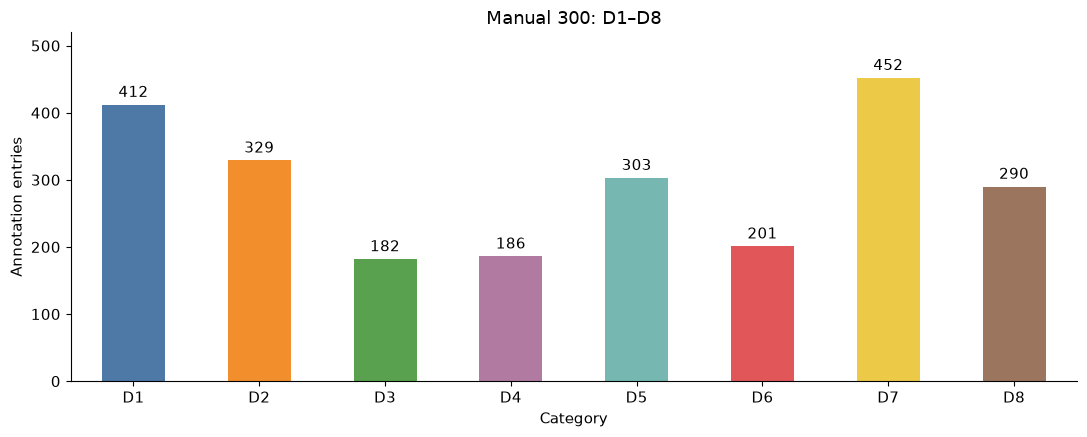

In [76]:
show_overall_distribution(manual, "Manual 300", "category")


Manual 300: Explicit and contextual visibility — overall counts and percentages


,Annotation entries,Distribution (%)
visibility,,
Explicit,749,31.95
Contextual,1595,68.05


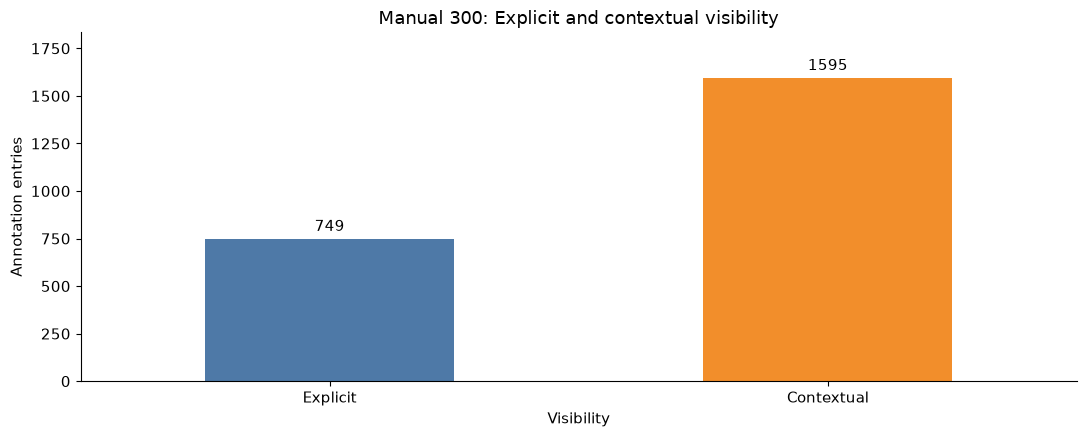

In [77]:
show_overall_distribution(manual, "Manual 300", "visibility")


### 3.2 D1–D8 by trajectory model

The count table is followed by the within-model percentage distribution and its chart.


Manual 300: D1–D8 by model — annotation counts


category,D1,D2,D3,D4,D5,D6,D7,D8
model,,,,,,,,
claude-fable-5,38,32,22,21,25,15,47,31
claude-opus-4-7,46,34,22,27,31,18,54,31
claude-opus-4-8,31,19,10,14,21,10,28,19
claude-sonnet-5,35,27,12,14,23,12,26,18
gemini-3-pro-preview,20,13,8,8,9,9,18,16
gemini-3.1-pro-preview,68,57,29,26,48,34,69,49
glm-5.1,18,12,11,7,16,9,21,14
gpt-5.5,43,39,23,23,35,24,49,36
gpt-5.6-luna,25,18,10,12,27,15,36,18


Manual 300: D1–D8 by model — within-row distribution (%)


category,D1 (%),D2 (%),D3 (%),D4 (%),D5 (%),D6 (%),D7 (%),D8 (%)
model,,,,,,,,
claude-fable-5,16.45,13.85,9.52,9.09,10.82,6.49,20.35,13.42
claude-opus-4-7,17.49,12.93,8.37,10.27,11.79,6.84,20.53,11.79
claude-opus-4-8,20.39,12.50,6.58,9.21,13.82,6.58,18.42,12.50
claude-sonnet-5,20.96,16.17,7.19,8.38,13.77,7.19,15.57,10.78
gemini-3-pro-preview,19.80,12.87,7.92,7.92,8.91,8.91,17.82,15.84
gemini-3.1-pro-preview,17.89,15.00,7.63,6.84,12.63,8.95,18.16,12.89
glm-5.1,16.67,11.11,10.19,6.48,14.81,8.33,19.44,12.96
gpt-5.5,15.81,14.34,8.46,8.46,12.87,8.82,18.01,13.24
gpt-5.6-luna,15.53,11.18,6.21,7.45,16.77,9.32,22.36,11.18


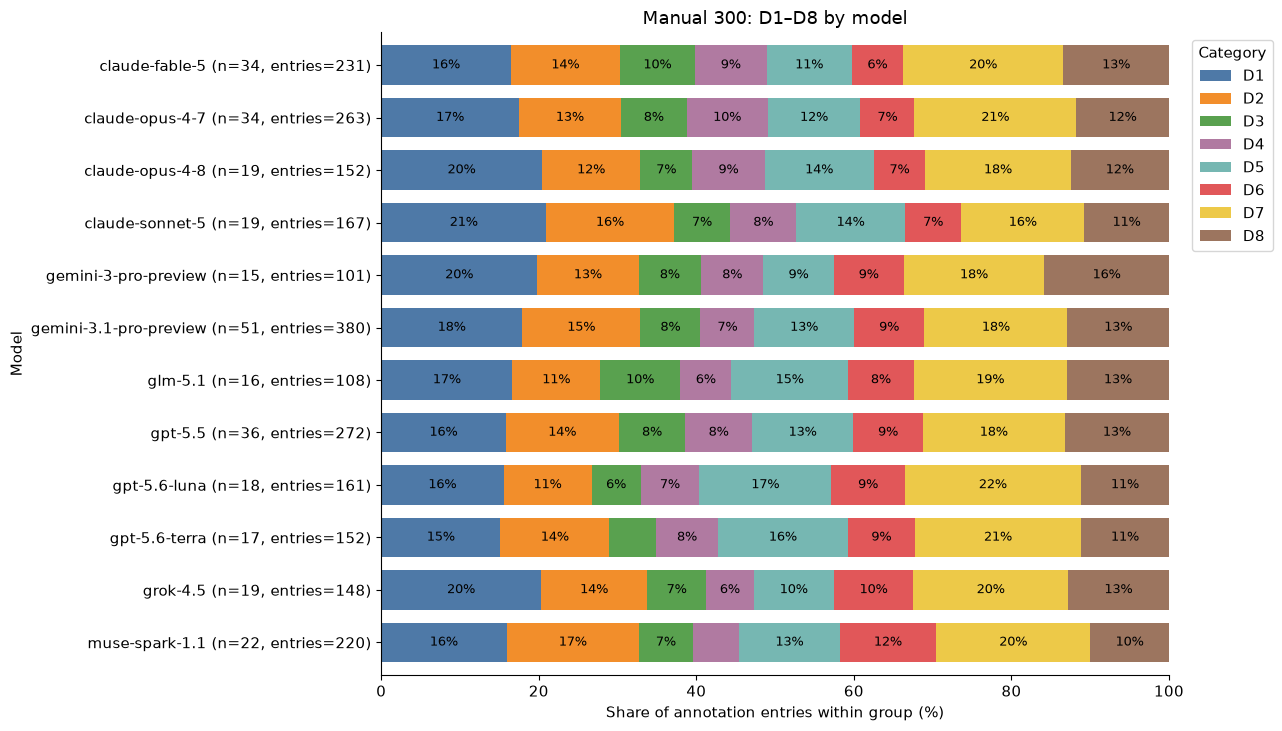

In [78]:
show_group_distribution(manual, "Manual 300", "model", "category")


### 3.3 D1–D8 by harness

The count table is followed by the within-harness percentage distribution and its chart.


Manual 300: D1–D8 by harness — annotation counts


category,D1,D2,D3,D4,D5,D6,D7,D8
harness,,,,,,,,
claude-code,128,92,50,54,90,43,121,79
codex,69,54,30,32,68,42,91,50
cursor-cli,30,20,11,9,15,15,29,19
gemini-cli,50,43,19,19,33,22,47,33
mini-swe-agent,35,37,15,13,28,27,43,22
terminus-2,100,83,57,59,69,52,121,87


Manual 300: D1–D8 by harness — within-row distribution (%)


category,D1 (%),D2 (%),D3 (%),D4 (%),D5 (%),D6 (%),D7 (%),D8 (%)
harness,,,,,,,,
claude-code,19.48,14.00,7.61,8.22,13.70,6.54,18.42,12.02
codex,15.83,12.39,6.88,7.34,15.60,9.63,20.87,11.47
cursor-cli,20.27,13.51,7.43,6.08,10.14,10.14,19.59,12.84
gemini-cli,18.80,16.17,7.14,7.14,12.41,8.27,17.67,12.41
mini-swe-agent,15.91,16.82,6.82,5.91,12.73,12.27,19.55,10.00
terminus-2,15.92,13.22,9.08,9.39,10.99,8.28,19.27,13.85


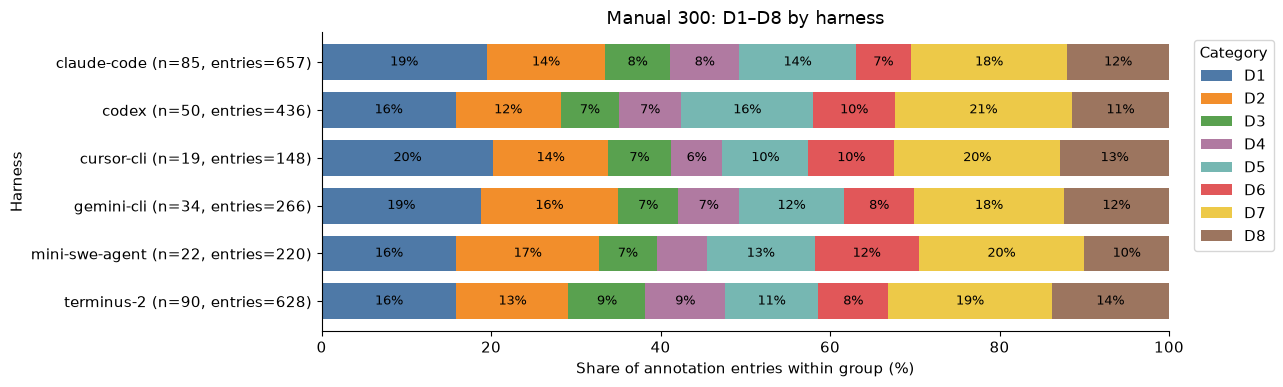

In [79]:
show_group_distribution(manual, "Manual 300", "harness", "category")


### 3.4 Explicit and contextual visibility by trajectory model

The count table is followed by the within-model percentage distribution and its chart.


Manual 300: Explicit/Contextual by model — annotation counts


visibility,Explicit,Contextual
model,,
claude-fable-5,83,148
claude-opus-4-7,92,171
claude-opus-4-8,70,82
claude-sonnet-5,50,114
gemini-3-pro-preview,6,95
gemini-3.1-pro-preview,143,237
glm-5.1,67,41
gpt-5.5,95,177
gpt-5.6-luna,28,132


Manual 300: Explicit/Contextual by model — within-row distribution (%)


visibility,Explicit (%),Contextual (%)
model,,
claude-fable-5,35.93,64.07
claude-opus-4-7,34.98,65.02
claude-opus-4-8,46.05,53.95
claude-sonnet-5,30.49,69.51
gemini-3-pro-preview,5.94,94.06
gemini-3.1-pro-preview,37.63,62.37
glm-5.1,62.04,37.96
gpt-5.5,34.93,65.07
gpt-5.6-luna,17.50,82.50


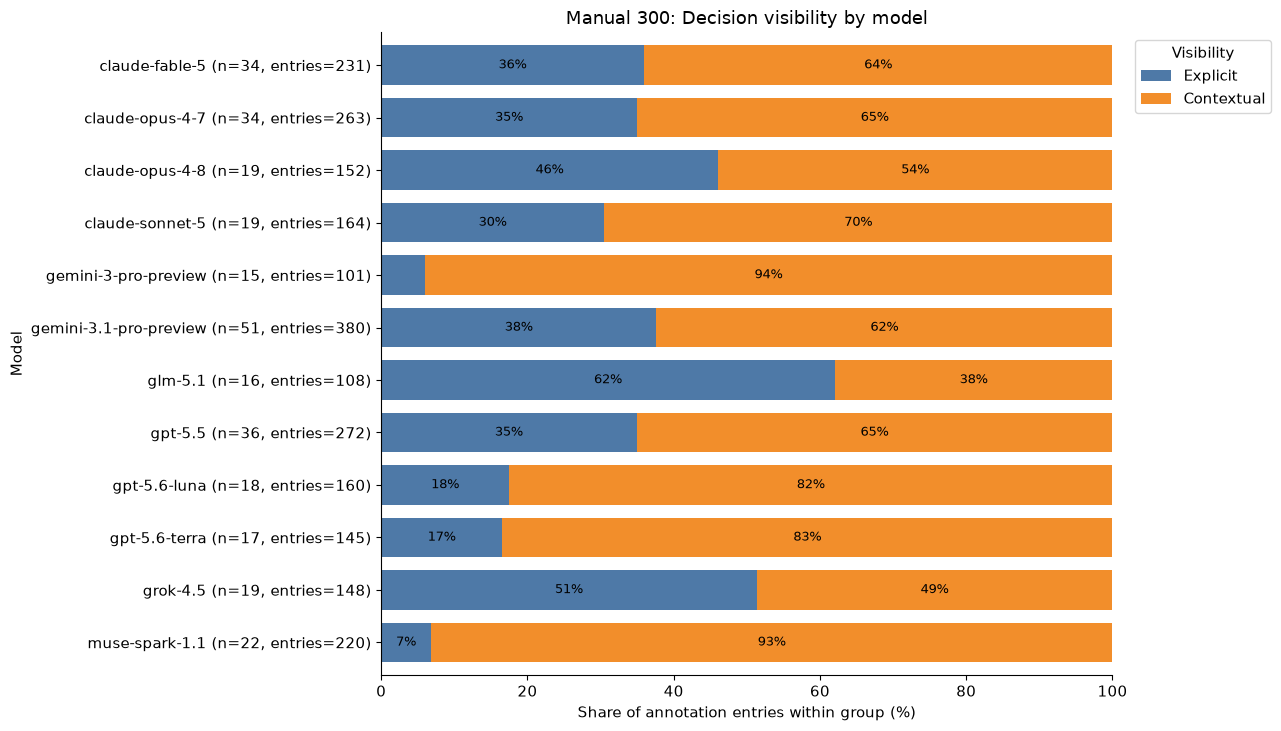

In [80]:
show_group_distribution(manual, "Manual 300", "model", "visibility")


### 3.5 Explicit and contextual visibility by harness

The count table is followed by the within-harness percentage distribution and its chart.


Manual 300: Explicit/Contextual by harness — annotation counts


visibility,Explicit,Contextual
harness,,
claude-code,339,315
codex,138,290
cursor-cli,76,72
gemini-cli,141,125
mini-swe-agent,15,205
terminus-2,40,588


Manual 300: Explicit/Contextual by harness — within-row distribution (%)


visibility,Explicit (%),Contextual (%)
harness,,
claude-code,51.83,48.17
codex,32.24,67.76
cursor-cli,51.35,48.65
gemini-cli,53.01,46.99
mini-swe-agent,6.82,93.18
terminus-2,6.37,93.63


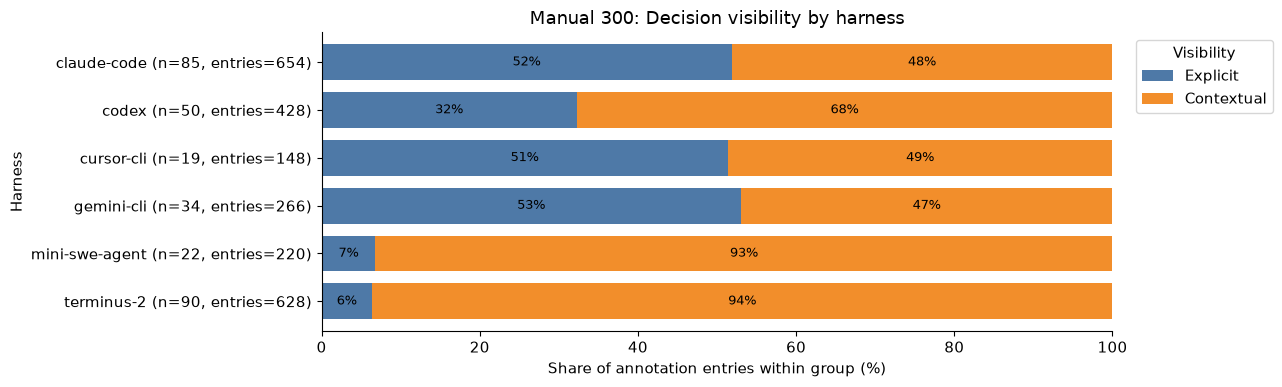

In [81]:
show_group_distribution(manual, "Manual 300", "harness", "visibility")


### 3.6 Model × harness combinations

Coverage, category counts and percentages, and visibility counts and percentages for each combination.


In [82]:
show_combinations(manual, "Manual 300")


Manual 300: model × harness coverage


trajectories  tasks  \
harness        model                                         
claude-code    claude-fable-5                    14     13   
               claude-opus-4-7                   17     15   
               claude-opus-4-8                   19     15   
               claude-sonnet-5                   19     15   
               glm-5.1                           16     15   
codex          gpt-5.5                           15     15   
               gpt-5.6-luna                      18     15   
               gpt-5.6-terra                     17     15   
cursor-cli     grok-4.5                          19     15   
gemini-cli     gemini-3.1-pro-preview            34     15   
mini-swe-agent muse-spark-1.1                    22     15   
terminus-2     claude-fable-5                    20     15   
               claude-opus-4-7                   17     15   
               gemini-3-pro-preview              15     15   
               gemini-3.1-pro-preview            17     15   
               gpt-5.5                           21     15   

                                       trajectories_with_entries  \
harness        model                                               
claude-code    claude-fable-5                                 14   
               claude-opus-4-7                                17   
               claude-opus-4-8                                19   
               claude-sonnet-5                                19   
               glm-5.1                                        16   
codex          gpt-5.5                                        15   
               gpt-5.6-luna                                   18   
               gpt-5.6-terra                                  17   
cursor-cli     grok-4.5                                       19   
gemini-cli     gemini-3.1-pro-preview                         34   
mini-swe-agent muse-spark-1.1                                 22   
terminus-2     claude-fable-5                                 20   
               claude-opus-4-7                                17   
               gemini-3-pro-preview                           15   
               gemini-3.1-pro-preview                         17   
               gpt-5.5                                        20   

                                       annotation_entries  \
harness        model                                        
claude-code    claude-fable-5                         106   
               claude-opus-4-7                        124   
               claude-opus-4-8                        152   
               claude-sonnet-5                        167   
               glm-5.1                                108   
codex          gpt-5.5                                123   
               gpt-5.6-luna                           161   
               gpt-5.6-terra                          152   
cursor-cli     grok-4.5                               148   
gemini-cli     gemini-3.1-pro-preview                 266   
mini-swe-agent muse-spark-1.1                         220   
terminus-2     claude-fable-5                         125   
               claude-opus-4-7                        139   
               gemini-3-pro-preview                   101   
               gemini-3.1-pro-preview                 114   
               gpt-5.5                                149   

                                       mean_entries_per_trajectory  \
harness        model                                                 
claude-code    claude-fable-5                                 7.57   
               claude-opus-4-7                                7.29   
               claude-opus-4-8                                8.00   
               claude-sonnet-5                                8.79   
               glm-5.1                                        6.75   
codex          gpt-5.5                                        8.20   
               gpt-5.6-luna           

Manual 300: D1–D8 by harness × model — annotation counts


category                               D1  D2  D3  D4  D5  D6  D7  D8
harness        model                                                 
claude-code    claude-fable-5          21  16   7  10  15   6  19  12
               claude-opus-4-7         23  18  10   9  15   6  27  16
               claude-opus-4-8         31  19  10  14  21  10  28  19
               claude-sonnet-5         35  27  12  14  23  12  26  18
               glm-5.1                 18  12  11   7  16   9  21  14
codex          gpt-5.5                 21  15  11   8  16  14  23  15
               gpt-5.6-luna            25  18  10  12  27  15  36  18
               gpt-5.6-terra           23  21   9  12  25  13  32  17
cursor-cli     grok-4.5                30  20  11   9  15  15  29  19
gemini-cli     gemini-3.1-pro-preview  50  43  19  19  33  22  47  33
mini-swe-agent muse-spark-1.1          35  37  15  13  28  27  43  22
terminus-2     claude-fable-5          17  16  15  11  10   9  28  19
               claude-opus-4-7         23  16  12  18  16  12  27  15
               gemini-3-pro-preview    20  13   8   8   9   9  18  16
               gemini-3.1-pro-preview  18  14  10   7  15  12  22  16
               gpt-5.5                 22  24  12  15  19  10  26  21

Manual 300: D1–D8 by harness × model — within-row distribution (%)


category                               D1 (%)  D2 (%)  D3 (%)  D4 (%)  D5 (%)  \
harness        model                                                            
claude-code    claude-fable-5           19.81   15.09    6.60    9.43   14.15   
               claude-opus-4-7          18.55   14.52    8.06    7.26   12.10   
               claude-opus-4-8          20.39   12.50    6.58    9.21   13.82   
               claude-sonnet-5          20.96   16.17    7.19    8.38   13.77   
               glm-5.1                  16.67   11.11   10.19    6.48   14.81   
codex          gpt-5.5                  17.07   12.20    8.94    6.50   13.01   
               gpt-5.6-luna             15.53   11.18    6.21    7.45   16.77   
               gpt-5.6-terra            15.13   13.82    5.92    7.89   16.45   
cursor-cli     grok-4.5                 20.27   13.51    7.43    6.08   10.14   
gemini-cli     gemini-3.1-pro-preview   18.80   16.17    7.14    7.14   12.41   
mini-swe-agent muse-spark-1.1           15.91   16.82    6.82    5.91   12.73   
terminus-2     claude-fable-5           13.60   12.80   12.00    8.80    8.00   
               claude-opus-4-7          16.55   11.51    8.63   12.95   11.51   
               gemini-3-pro-preview     19.80   12.87    7.92    7.92    8.91   
               gemini-3.1-pro-preview   15.79   12.28    8.77    6.14   13.16   
               gpt-5.5                  14.77   16.11    8.05   10.07   12.75   

category                               D6 (%)  D7 (%)  D8 (%)  
harness        model                                           
claude-code    claude-fable-5            5.66   17.92   11.32  
               claude-opus-4-7           4.84   21.77   12.90  
               claude-opus-4-8           6.58   18.42   12.50  
               claude-sonnet-5           7.19   15.57   10.78  
               glm-5.1                   8.33   19.44   12.96  
codex          gpt-5.5                  11.38   18.70   12.20  
               gpt-5.6-luna              9.32   22.36   11.18  
               gpt-5.6-terra             8.55   21.05   11.18  
cursor-cli     grok-4.5                 10.14   19.59   12.84  
gemini-cli     gemini-3.1-pro-preview    8.27   17.67   12.41  
mini-swe-agent muse-spark-1.1           12.27   19.55   10.00  
terminus-2     claude-fable-5            7.20   22.40   15.20  
               claude-opus-4-7           8.63   19.42   10.79  
               gemini-3-pro-preview      8.91   17.82   15.84  
               gemini-3.1-pro-preview   10.53   19.30   14.04  
               gpt-5.5                   6.71   17.45   14.09

Manual 300: Explicit/Contextual by harness × model — annotation counts


visibility                             Explicit  Contextual
harness        model                                       
claude-code    claude-fable-5                73          33
               claude-opus-4-7               79          45
               claude-opus-4-8               70          82
               claude-sonnet-5               50         114
               glm-5.1                       67          41
codex          gpt-5.5                       86          37
               gpt-5.6-luna                  28         132
               gpt-5.6-terra                 24         121
cursor-cli     grok-4.5                      76          72
gemini-cli     gemini-3.1-pro-preview       141         125
mini-swe-agent muse-spark-1.1                15         205
terminus-2     claude-fable-5                10         115
               claude-opus-4-7               13         126
               gemini-3-pro-preview           6          95
               gemini-3.1-pro-preview         2         112
               gpt-5.5                        9         140

Manual 300: Explicit/Contextual by harness × model — within-row distribution (%)


visibility                             Explicit (%)  Contextual (%)
harness        model                                               
claude-code    claude-fable-5                 68.87           31.13
               claude-opus-4-7                63.71           36.29
               claude-opus-4-8                46.05           53.95
               claude-sonnet-5                30.49           69.51
               glm-5.1                        62.04           37.96
codex          gpt-5.5                        69.92           30.08
               gpt-5.6-luna                   17.50           82.50
               gpt-5.6-terra                  16.55           83.45
cursor-cli     grok-4.5                       51.35           48.65
gemini-cli     gemini-3.1-pro-preview         53.01           46.99
mini-swe-agent muse-spark-1.1                  6.82           93.18
terminus-2     claude-fable-5                  8.00           92.00
               claude-opus-4-7                 9.35           90.65
               gemini-3-pro-preview            5.94           94.06
               gemini-3.1-pro-preview          1.75           98.25
               gpt-5.5                         6.04           93.96

### 3.7 Findings and interpretation

The summary reports the most frequent category and visibility composition overall and per model and harness. These distributions describe the recorded annotations; they do not establish causal effects of a model or harness.


In [83]:
show_findings(manual, "Manual 300")


Manual 300: 300 trajectories across 15 tasks; 2,355 category annotation entries.
Most frequent category: D7 — Verification choice (452 entries; 19.19%).
Visibility denominator: 2,344 valid entries.
Visibility: 31.95% Explicit; 68.05% Contextual.
Manual 300: summary by model


,trajectories,tasks,annotation_entries,mean_entries_per_trajectory,median_entries_per_trajectory,most_frequent_category,most_frequent_category_pct,valid_visibility_entries,explicit_pct,contextual_pct
model,,,,,,,,,,
claude-fable-5,34,15,231,6.79,6.5,D7,20.35,231,35.93,64.07
claude-opus-4-7,34,15,263,7.74,7.0,D7,20.53,263,34.98,65.02
claude-opus-4-8,19,15,152,8.00,7.0,D1,20.39,152,46.05,53.95
claude-sonnet-5,19,15,167,8.79,7.0,D1,20.96,164,30.49,69.51
gemini-3-pro-preview,15,15,101,6.73,6.0,D1,19.80,101,5.94,94.06
gemini-3.1-pro-preview,51,15,380,7.45,7.0,D7,18.16,380,37.63,62.37
glm-5.1,16,15,108,6.75,6.0,D7,19.44,108,62.04,37.96
gpt-5.5,36,15,272,7.56,7.0,D7,18.01,272,34.93,65.07
gpt-5.6-luna,18,15,161,8.94,8.0,D7,22.36,160,17.50,82.50


Manual 300: summary by harness


,trajectories,tasks,annotation_entries,mean_entries_per_trajectory,median_entries_per_trajectory,most_frequent_category,most_frequent_category_pct,valid_visibility_entries,explicit_pct,contextual_pct
harness,,,,,,,,,,
claude-code,85,15,657,7.73,7.0,D1,19.48,654,51.83,48.17
codex,50,15,436,8.72,8.0,D7,20.87,428,32.24,67.76
cursor-cli,19,15,148,7.79,7.0,D1,20.27,148,51.35,48.65
gemini-cli,34,15,266,7.82,7.0,D1,18.80,266,53.01,46.99
mini-swe-agent,22,15,220,10.00,9.0,D7,19.55,220,6.82,93.18
terminus-2,90,15,628,6.98,6.5,D7,19.27,628,6.37,93.63


## 4. V1 and V2 against manual ground truth

The manual annotation workbook from Section 3 is the ground truth for both V1 and V2. The selected reference path is displayed below. Both predictions use the same 300 trajectories and 5,196 recorded steps; all 15 tasks remain included.

The comparison unit is **task + Trial ID + recorded step**. Each step is represented by a set of D1–D8 labels. Repeated occurrences of one category in a step count once here, while Sections 1–3 retain all category assignments. Decisions recorded at different steps are disagreements in this section. This measures label agreement, not semantic matching of decision descriptions.

Precision = TP / (TP + FP), recall = TP / (TP + FN), and F1 = 2TP / (2TP + FP + FN). A zero denominator produces 0. Micro scores pool assignments, macro scores average over all listed labels, and weighted F1 uses **manual-reference support**. Blank manual cells are treated as empty reference sets for this requested comparison; they do not independently demonstrate review completeness.

Visibility presence compares Explicit/Contextual sets. Joint evaluation requires category and visibility to match. Conditional visibility compares only matching step/category pairs with one unambiguous visibility in each workbook. Missing visibility is not a third class.

**Reference provenance:** the taxonomy and visibility for git-leak-recovery, count-dataset-tokens, modernize-scientific-stack, multi-source-data-merger and pytorch-model-recovery were copied from V2 into the manual workbook. Their agreement with V2 is therefore not independent validation. Section 4.3 marks these tasks and reports the full sample and the other ten tasks separately. Source workbooks are not changed.


In [84]:
def step_label_sets(data, field):
    keys = ["task", "trial_id", "step"]
    result = {
        tuple(values): set()
        for values in data["steps"][keys].itertuples(index=False, name=None)
    }
    for row in data["entries"].itertuples(index=False):
        key = (row.task, row.trial_id, row.step)
        if field == "category":
            result[key].add(row.category)
        elif field == "visibility" and row.visibility in VISIBILITIES:
            result[key].add(row.visibility)
        elif field == "joint" and row.visibility in VISIBILITIES:
            result[key].add(f"{row.category} / {row.visibility}")
    return result


def safe_ratio(numerator, denominator):
    return numerator / denominator if denominator else 0.0


def compare_label_sets(reference, prediction, labels):
    if reference.keys() != prediction.keys():
        raise ValueError("Reference and prediction comparison identities do not match.")
    rows = []
    for label in labels:
        tp = sum(label in reference[k] and label in prediction[k] for k in reference)
        fp = sum(label not in reference[k] and label in prediction[k] for k in reference)
        fn = sum(label in reference[k] and label not in prediction[k] for k in reference)
        rows.append({
            "Label": label, "TP": tp, "FP": fp, "FN": fn,
            "Reference support": tp + fn, "Prediction count": tp + fp,
            "Precision": safe_ratio(tp, tp + fp),
            "Recall": safe_ratio(tp, tp + fn),
            "F1": safe_ratio(2 * tp, 2 * tp + fp + fn),
        })
    report = pd.DataFrame(rows).set_index("Label")
    tp, fp, fn = (int(report[column].sum()) for column in ["TP", "FP", "FN"])
    support = int(report["Reference support"].sum())
    summary = {
        "Micro precision": safe_ratio(tp, tp + fp),
        "Micro recall": safe_ratio(tp, tp + fn),
        "Micro F1": safe_ratio(2 * tp, 2 * tp + fp + fn),
        "Macro precision": float(report["Precision"].mean()),
        "Macro recall": float(report["Recall"].mean()),
        "Macro F1": float(report["F1"].mean()),
        "Weighted F1": safe_ratio(
            float((report["F1"] * report["Reference support"]).sum()), support
        ),
        "TP": tp, "FP": fp, "FN": fn,
    }
    return report, summary


def plot_precision_recall_f1(report, title):
    ax = report[["Precision", "Recall", "F1"]].plot.bar(
        figsize=(12, 5), rot=0, color=["#4E79A7", "#F28E2B", "#59A14F"]
    )
    ax.set(title=title, xlabel="Label", ylabel="Score (0–1)", ylim=(0, 1.12))
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", padding=2, fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_version_prf(reports, title):
    fig, axes = plt.subplots(1, len(reports), figsize=(15, 4.8), sharey=True, squeeze=False)
    for ax, (version, report) in zip(axes.flat, reports.items()):
        report[["Precision", "Recall", "F1"]].plot.bar(
            ax=ax, rot=0, color=["#4E79A7", "#F28E2B", "#59A14F"], legend=False
        )
        ax.set(title=f"{version} against manual", xlabel="Label", ylabel="Score (0–1)", ylim=(0, 1.12))
        for container in ax.containers:
            ax.bar_label(container, fmt="%.2f", padding=2, fontsize=7)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.95), ncol=3)
    fig.suptitle(title, y=1.02)
    plt.tight_layout(rect=(0, 0, 1, 0.89))
    plt.show()


### 4.1 Decision detection and taxonomy precision, recall, and F1

Decision detection asks whether a step has any category annotation. Taxonomy evaluation asks which D1–D8 labels occur in the step. These are separate comparisons. True negatives are not included in precision, recall, or F1.


In [85]:
GROUND_TRUTH_WORKBOOK_PATH = MANUAL_WORKBOOK_PATH
ground_truth = manual
prediction_datasets = {"V1": gpt_v1, "V2": gpt_v2}
V2_COPIED_REFERENCE_TASKS = {
    "git-leak-recovery", "count-dataset-tokens", "modernize-scientific-stack",
    "multi-source-data-merger", "pytorch-model-recovery",
}
print(f"Ground truth: {GROUND_TRUTH_WORKBOOK_PATH}")
for version, data in prediction_datasets.items():
    check_same_sample(ground_truth, data, version, reference_name="Manual")

manual_categories = step_label_sets(ground_truth, "category")
prediction_categories = {v: step_label_sets(d, "category") for v, d in prediction_datasets.items()}
manual_detection = {k: {"Decision"} if labels else set() for k, labels in manual_categories.items()}
taxonomy_reports, taxonomy_scores, detection_reports, detection_scores = {}, {}, {}, {}
step_agreement_rows = []
for version, prediction in prediction_categories.items():
    taxonomy_reports[version], taxonomy_scores[version] = compare_label_sets(manual_categories, prediction, CATEGORIES)
    detection = {k: {"Decision"} if labels else set() for k, labels in prediction.items()}
    detection_reports[version], detection_scores[version] = compare_label_sets(manual_detection, detection, ["Decision"])
    active = [k for k in manual_categories if manual_categories[k] or prediction[k]]
    step_agreement_rows.append({
        "Prediction": version, "Compared steps": len(manual_categories),
        "Steps annotated in reference or prediction": len(active),
        "Exact category-set agreement, all steps": safe_ratio(sum(manual_categories[k] == prediction[k] for k in manual_categories), len(manual_categories)),
        "Exact category-set agreement, annotated union": safe_ratio(sum(manual_categories[k] == prediction[k] for k in active), len(active)),
        "Mean category Jaccard, annotated union": safe_ratio(sum(len(manual_categories[k] & prediction[k]) / len(manual_categories[k] | prediction[k]) for k in active), len(active)),
    })

print("Decision detection against manual")
display(pd.concat(detection_reports, names=["Prediction", "Label"]).round(4))
print("D1–D8 taxonomy against manual")
display(pd.concat(taxonomy_reports, names=["Prediction", "Label"]).round(4))
step_evaluation_summary = pd.concat({
    v: pd.DataFrame({"Decision detection": detection_scores[v], "D1–D8 taxonomy": taxonomy_scores[v]}).T
    for v in prediction_datasets
}, names=["Prediction", "Evaluation"])
display(step_evaluation_summary.round(4))
step_agreement = pd.DataFrame(step_agreement_rows).set_index("Prediction")
display(step_agreement.round(4))


Ground truth: D:\Studies\UZH-M.Sc\THESIS\design-decisions-by-LLMs\outputs\Final Annotations\terminalbench21_task_annotated_manual.xlsx
V1 and Manual cover the same 300 trajectories and recorded steps.
V2 and Manual cover the same 300 trajectories and recorded steps.
Decision detection against manual


,,TP,FP,FN,Reference support,Prediction count,Precision,Recall,F1
Prediction,Label,,,,,,,,
V1,Decision,1741,335,76,1817,2076,0.8386,0.9582,0.8944
V2,Decision,1469,255,348,1817,1724,0.8521,0.8085,0.8297


D1–D8 taxonomy against manual


TP   FP   FN  Reference support  Prediction count  \
Prediction Label                                                       
V1         D1     382  134   30                412               516   
           D2     283   25    9                292               308   
           D3     164  100   10                174               264   
           D4     154   34   25                179               188   
           D5     240   66   39                279               306   
           D6     186   98   15                201               284   
           D7     401  122   39                440               523   
           D8     278    9   12                290               287   
V2         D1     281   92  131                412               373   
           D2     188   40  104                292               228   
           D3     133   26   41                174               159   
           D4     139   67   40                179               206   
           D5     245   85   34                279               330   
           D6      94   73  107                201               167   
           D7     334  173  106                440               507   
           D8     270   14   20                290               284   

                  Precision  Recall      F1  
Prediction Label                             
V1         D1        0.7403  0.9272  0.8233  
           D2        0.9188  0.9692  0.9433  
           D3        0.6212  0.9425  0.7489  
           D4        0.8191  0.8603  0.8392  
           D5        0.7843  0.8602  0.8205  
           D6        0.6549  0.9254  0.7670  
           D7        0.7667  0.9114  0.8328  
           D8        0.9686  0.9586  0.9636  
V2         D1        0.7534  0.6820  0.7159  
           D2        0.8246  0.6438  0.7231  
           D3        0.8365  0.7644  0.7988  
           D4        0.6748  0.7765  0.7221  
           D5        0.7424  0.8781  0.8046  
           D6        0.5629  0.4677  0.5109  
           D7        0.6588  0.7591  0.7054  
           D8        0.9507  0.9310  0.9408

Micro precision  Micro recall  Micro F1  \
Prediction Evaluation                                                    
V1         Decision detection           0.8386        0.9582    0.8944   
           D1–D8 taxonomy               0.7803        0.9210    0.8448   
V2         Decision detection           0.8521        0.8085    0.8297   
           D1–D8 taxonomy               0.7471        0.7428    0.7450   

                               Macro precision  Macro recall  Macro F1  \
Prediction Evaluation                                                    
V1         Decision detection           0.8386        0.9582    0.8944   
           D1–D8 taxonomy               0.7843        0.9193    0.8423   
V2         Decision detection           0.8521        0.8085    0.8297   
           D1–D8 taxonomy               0.7505        0.7378    0.7402   

                               Weighted F1      TP     FP     FN  
Prediction Evaluation                                             
V1         Decision detection       0.8944  1741.0  335.0   76.0  
           D1–D8 taxonomy           0.8488  2088.0  588.0  179.0  
V2         Decision detection       0.8297  1469.0  255.0  348.0  
           D1–D8 taxonomy           0.7431  1684.0  570.0  583.0

,Compared steps,Steps annotated in reference or prediction,"Exact category-set agreement, all steps","Exact category-set agreement, annotated union","Mean category Jaccard, annotated union"
Prediction,,,,,
V1,5196,2152,0.8789,0.7077,0.7520
V2,5196,2072,0.8289,0.5709,0.6088


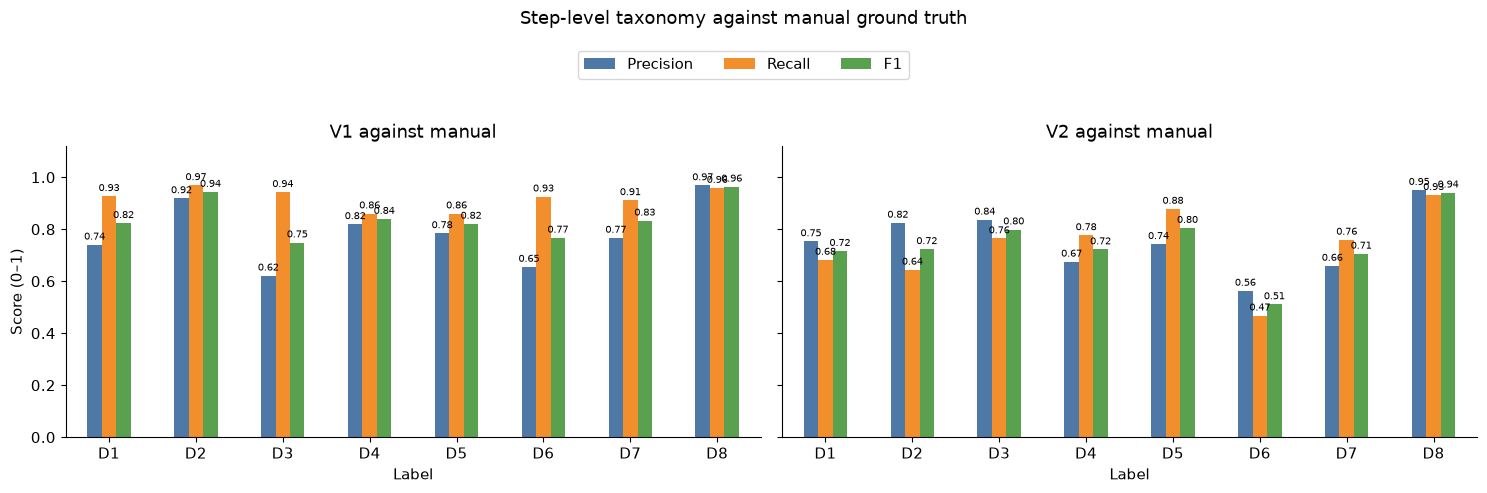

In [86]:
plot_version_prf(taxonomy_reports, "Step-level taxonomy against manual ground truth")


### 4.2 Visibility and joint category–visibility evaluation

Both V1 and V2 are compared with the manual reference. Visibility-presence scores include steps where only the reference or prediction records visibility. Joint scores require the category–visibility pair to match. Conditional visibility is assessed separately on matched, unambiguous step/category pairs.


In [87]:
manual_visibility = step_label_sets(ground_truth, "visibility")
manual_joint = step_label_sets(ground_truth, "joint")
joint_labels = [f"{c} / {v}" for c in CATEGORIES for v in VISIBILITIES]
visibility_reports, visibility_scores, joint_reports, joint_scores = {}, {}, {}, {}
for version, data in prediction_datasets.items():
    visibility_reports[version], visibility_scores[version] = compare_label_sets(manual_visibility, step_label_sets(data, "visibility"), VISIBILITIES)
    joint_reports[version], joint_scores[version] = compare_label_sets(manual_joint, step_label_sets(data, "joint"), joint_labels)
display(pd.concat(visibility_reports, names=["Prediction", "Label"]).round(4))
display(pd.concat({
    v: pd.DataFrame({"Visibility presence": visibility_scores[v], "Joint category and visibility": joint_scores[v]}).T
    for v in prediction_datasets
}, names=["Prediction", "Evaluation"]).round(4))
print("Joint label details against manual")
display(pd.concat(joint_reports, names=["Prediction", "Label"]).round(4))


TP   FP   FN  Reference support  Prediction count  \
Prediction Label                                                             
V1         Explicit     576  208  108                684               784   
           Contextual  1108  284   74               1182              1392   
V2         Explicit     532  266  152                684               798   
           Contextual   832  188  350               1182              1020   

                       Precision  Recall      F1  
Prediction Label                                  
V1         Explicit       0.7347  0.8421  0.7847  
           Contextual     0.7960  0.9374  0.8609  
V2         Explicit       0.6667  0.7778  0.7179  
           Contextual     0.8157  0.7039  0.7557

Micro precision  Micro recall  \
Prediction Evaluation                                                     
V1         Visibility presence                     0.7739        0.9025   
           Joint category and visibility           0.7100        0.8452   
V2         Visibility presence                     0.7503        0.7310   
           Joint category and visibility           0.6625        0.6689   

                                          Micro F1  Macro precision  \
Prediction Evaluation                                                 
V1         Visibility presence              0.8333           0.7653   
           Joint category and visibility    0.7717           0.6776   
V2         Visibility presence              0.7405           0.7412   
           Joint category and visibility    0.6656           0.6301   

                                          Macro recall  Macro F1  Weighted F1  \
Prediction Evaluation                                                           
V1         Visibility presence                  0.8897    0.8228       0.8330   
           Joint category and visibility        0.8073    0.7306       0.7768   
V2         Visibility presence                  0.7408    0.7368       0.7418   
           Joint category and visibility        0.6570    0.6354       0.6656   

                                              TP     FP     FN  
Prediction Evaluation                                           
V1         Visibility presence            1684.0  492.0  182.0  
           Joint category and visibility  1922.0  785.0  352.0  
V2         Visibility presence            1364.0  454.0  502.0  
           Joint category and visibility  1521.0  775.0  753.0

Joint label details against manual


TP   FP   FN  Reference support  \
Prediction Label                                               
V1         D1 / Explicit    128   54   18                146   
           D1 / Contextual  246   88   20                266   
           D2 / Explicit     31   36   22                 53   
           D2 / Contextual  215   32   29                244   
           D3 / Explicit     28   48    9                 37   
           D3 / Contextual  113   85   24                137   
           D4 / Explicit     17   10   12                 29   
           D4 / Contextual  125   40   25                150   
           D5 / Explicit     54   33   20                 74   
           D5 / Contextual  166   64   41                207   
           D6 / Explicit     44   35   13                 57   
           D6 / Contextual  127   78   17                144   
           D7 / Explicit    139   52   38                177   
           D7 / Contextual  231  101   32                263   
           D8 / Explicit    137    5   28                165   
           D8 / Contextual  121   24    4                125   
V2         D1 / Explicit    109   40   37                146   
           D1 / Contextual  161   63  105                266   
           D2 / Explicit     38   41   15                 53   
           D2 / Contextual  138   29  106                244   
           D3 / Explicit     21   33   16                 37   
           D3 / Contextual   85   24   52                137   
           D4 / Explicit     16   17   13                 29   
           D4 / Contextual  111   67   39                150   
           D5 / Explicit     52   49   22                 74   
           D5 / Contextual  160   81   47                207   
           D6 / Explicit     28   36   29                 57   
           D6 / Contextual   49   54   95                144   
           D7 / Explicit    124   93   53                177   
           D7 / Contextual  177  116   86                263   
           D8 / Explicit    154   21   11                165   
           D8 / Contextual   98   11   27                125   

                            Prediction count  Precision  Recall      F1  
Prediction Label                                                         
V1         D1 / Explicit                 182     0.7033  0.8767  0.7805  
           D1 / Contextual               334     0.7365  0.9248  0.8200  
           D2 / Explicit                  67     0.4627  0.5849  0.5167  
           D2 / Contextual               247     0.8704  0.8811  0.8758  
           D3 / Explicit                  76     0.3684  0.7568  0.4956  
           D3 / Contextual               198     0.5707  0.8248  0.6746  
           D4 / Explicit                  27     0.6296  0.5862  0.6071  
           D4 / Contextual               165     0.7576  0.8333  0.7937  
           D5 / Explicit                  87     0.6207  0.7297  0.6708  
           D5 / Contextual               230     0.7217  0.8019  0.7597  
           D6 / Explicit                  79     0.5570  0.7719  0.6471  
           D6 / Contextual               205     0.6195  0.8819  0.7278  
           D7 / Explicit                 191     0.7277  0.7853  0.7554  
           D7 / Contextual               332     0.6958  0.8783  0.7765  
           D8 / Explicit                 142     0.9648  0.8303  0.8925  
           D8 / Contextual               145     0.8345  0.9680  0.8963  
V2         D1 / Explicit                 149     0.7315  0.7466  0.7390  
           D1 / Contextual               224     0.7188  0.6053  0.6571  
           D2 / Explicit                  79     0.4810  0.7170  0.5758  
           D2 / Contextual               167     0.8263  0.5656  0.6715  
           D3 / Explicit                  54     0.3889  0.5676  0.4615  
           D3 / Contextual               109     0.7798  0.6204  0.6911  
           D4 / Explicit                  33     0.4848  0.5517  0.5161  
  

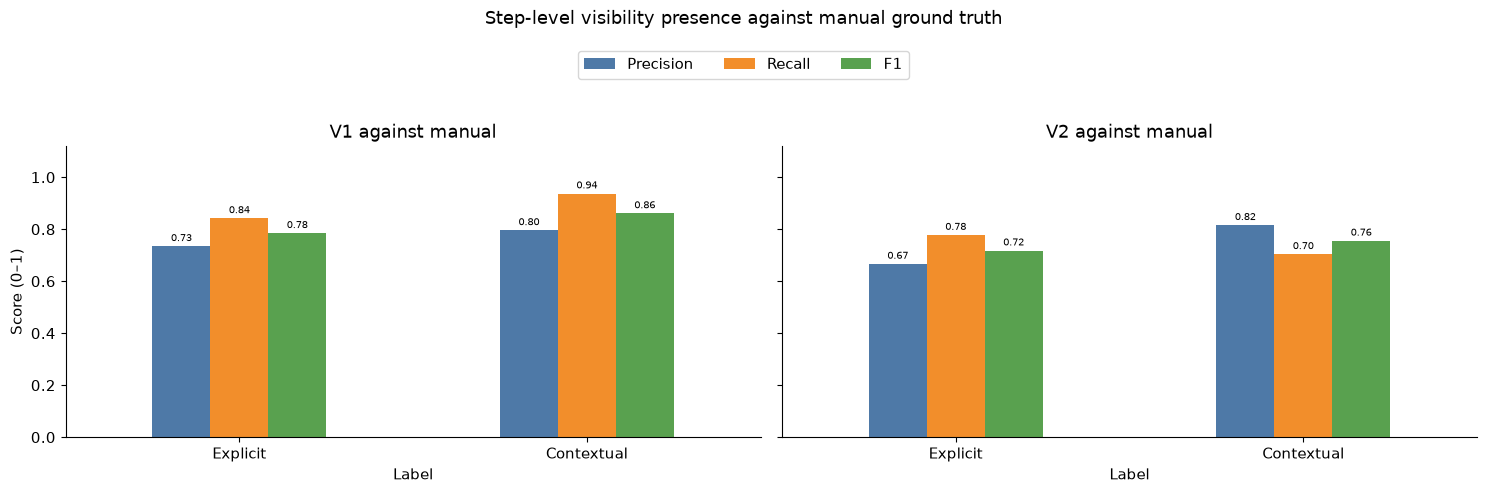

In [88]:
plot_version_prf(visibility_reports, "Step-level visibility presence against manual ground truth")


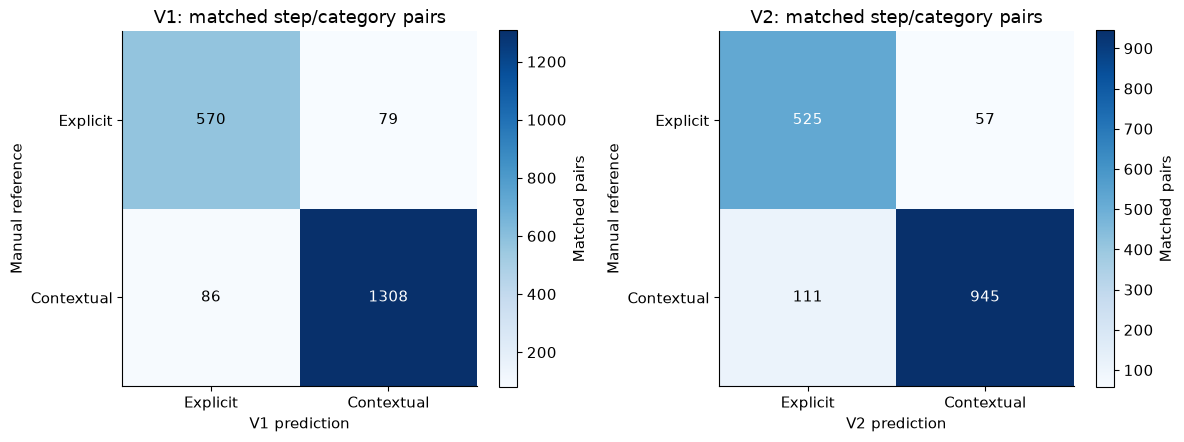

Explicit  Contextual
Prediction Manual reference                      
V1         Explicit               570          79
           Contextual              86        1308
V2         Explicit               525          57
           Contextual             111         945

,Common step–category pairs,Pairs with unambiguous visibility in both,Pairs excluded for missing or ambiguous visibility,Conditional visibility agreement
Prediction,,,,
V1,2088,2043,45,0.9192
V2,1684,1638,46,0.8974


In [89]:
def step_category_visibility(data):
    result = {}
    for row in data["entries"].itertuples(index=False):
        key = (row.task, row.trial_id, row.step, row.category)
        result.setdefault(key, set())
        if row.visibility in VISIBILITIES:
            result[key].add(row.visibility)
    return result

manual_category_visibility = step_category_visibility(ground_truth)
visibility_confusions, conditional_visibility_rows = {}, []
fig, axes = plt.subplots(1, len(prediction_datasets), figsize=(12, 4.5), squeeze=False)
for ax, (version, data) in zip(axes.flat, prediction_datasets.items()):
    predicted = step_category_visibility(data)
    common = manual_category_visibility.keys() & predicted.keys()
    confusion = pd.DataFrame(0, index=VISIBILITIES, columns=VISIBILITIES)
    eligible = []
    for key in sorted(common):
        ref, pred = manual_category_visibility[key], predicted[key]
        if len(ref) == len(pred) == 1:
            a, b = next(iter(ref)), next(iter(pred))
            confusion.loc[a, b] += 1
            eligible.append((a, b))
    confusion.index.name = "Manual reference"
    confusion.columns.name = f"{version} prediction"
    visibility_confusions[version] = confusion
    conditional_visibility_rows.append({
        "Prediction": version, "Common step–category pairs": len(common),
        "Pairs with unambiguous visibility in both": len(eligible),
        "Pairs excluded for missing or ambiguous visibility": len(common)-len(eligible),
        "Conditional visibility agreement": safe_ratio(sum(a == b for a,b in eligible),len(eligible)),
    })
    image = ax.imshow(confusion.to_numpy(), cmap="Blues")
    ax.set_xticks(range(2), VISIBILITIES)
    ax.set_yticks(range(2), VISIBILITIES)
    ax.set(xlabel=f"{version} prediction", ylabel="Manual reference", title=f"{version}: matched step/category pairs")
    for i in range(2):
        for j in range(2):
            ax.text(j,i,str(confusion.iloc[i,j]),ha="center",va="center",
                    color="white" if confusion.iloc[i,j] > confusion.to_numpy().max()/2 else "black")
    fig.colorbar(image, ax=ax, label="Matched pairs")
plt.tight_layout()
plt.show()
display(pd.concat(visibility_confusions, names=["Prediction", "Manual reference"]))
conditional_visibility_summary = pd.DataFrame(conditional_visibility_rows).set_index("Prediction")
display(conditional_visibility_summary.round(4))


### 4.3 Taxonomy agreement by task, reference provenance and disagreements

Per-task scores use the same multi-label step-level rule for both predictions. The five tasks initially copied from V2 are marked in the provenance column. The scope summary separates these five tasks from the other ten while retaining the full-sample result. Disagreements show manual and predicted category sets, missing and additional labels, and the prediction version.


,,Compared steps,Micro precision,Micro recall,Micro F1,Macro F1,Reference provenance
Task,Prediction,,,,,,
cancel-async-tasks,V1,214,0.9000,0.9854,0.9408,0.7071,Other manual tasks
count-dataset-tokens,V1,394,0.4369,0.8710,0.5819,0.5550,Initially copied from V2
fix-git,V1,335,0.6403,0.9368,0.7607,0.4852,Other manual tasks
git-leak-recovery,V1,302,0.6984,0.9462,0.8037,0.5170,Initially copied from V2
headless-terminal,V1,320,1.0000,1.0000,1.0000,0.8750,Other manual tasks
kv-store-grpc,V1,271,0.8633,0.9836,0.9195,0.6858,Other manual tasks
llm-inference-batching-schedule,V1,472,1.0000,1.0000,1.0000,1.0000,Other manual tasks
modernize-scientific-stack,V1,173,0.7548,0.9590,0.8448,0.7263,Initially copied from V2
mteb-retrieve,V1,368,1.0000,1.0000,1.0000,1.0000,Other manual tasks


,,Trajectories,Compared steps,Micro precision,Micro recall,Micro F1,Macro precision,Macro recall,Macro F1,Weighted F1,TP,FP,FN
Scope,Prediction,,,,,,,,,,,,
Full manual workbook,V1,300,5196,0.7803,0.9210,0.8448,0.7843,0.9193,0.8423,0.8488,2088,588,179
Other ten tasks,V1,200,3858,0.8431,0.9377,0.8879,0.8355,0.9333,0.8786,0.8909,1521,283,101
Five tasks initially copied from V2,V1,100,1338,0.6502,0.8791,0.7475,0.6699,0.8836,0.7421,0.7686,567,305,78
Full manual workbook,V2,300,5196,0.7471,0.7428,0.7450,0.7505,0.7378,0.7402,0.7431,1684,570,583
Other ten tasks,V2,200,3858,0.6457,0.6406,0.6431,0.6577,0.6434,0.6439,0.6404,1039,570,583
Five tasks initially copied from V2,V2,100,1338,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,645,0,0


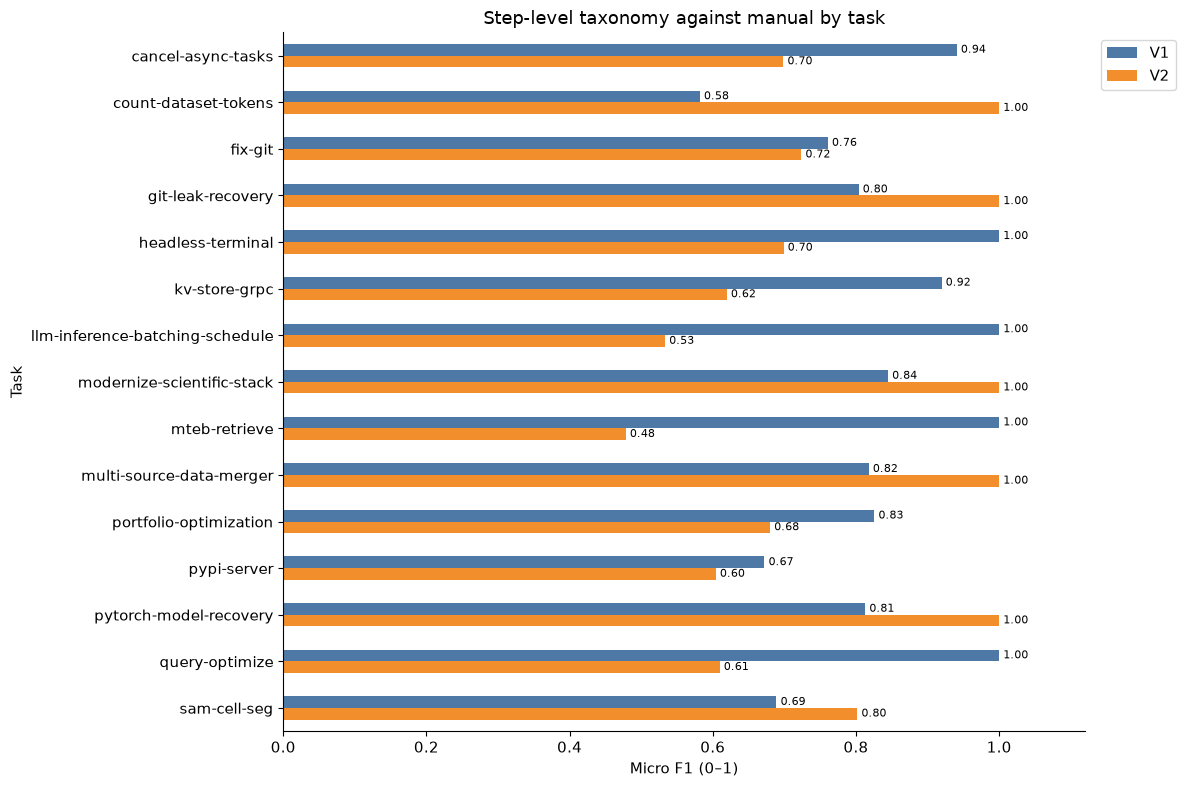

Step disagreements against manual by prediction


,Disagreeing steps
Prediction,
V1,629
V2,889


,Prediction,Task,Trial ID,Step,Manual categories,Predicted categories,Missing from prediction,Additional in prediction
0,V1,cancel-async-tasks,0285f4c5-fee2-5151-ba94-e1bb837f0916,2,,D3,,D3
1,V1,cancel-async-tasks,1f42f951-40e6-5b08-aded-3ac887545534,2,D2,D1,D2,D1
2,V1,cancel-async-tasks,1f42f951-40e6-5b08-aded-3ac887545534,20,,D7,,D7
3,V1,cancel-async-tasks,1f42f951-40e6-5b08-aded-3ac887545534,22,,D3,,D3
4,V1,cancel-async-tasks,221a2d99-7f7e-5722-946b-8d28a7691b95,3,"D1, D2, D3","D1, D2, D3, D7",,D7
5,V1,cancel-async-tasks,2b6f0479-e1dc-5344-b111-cb4b147866b2,4,D2,"D2, D7",,D7
6,V1,cancel-async-tasks,491f5d14-7869-526b-8f2c-0f7edd01583a,9,,D7,,D7
7,V1,cancel-async-tasks,7de59d7f-eb79-5506-b02a-1428326d20b2,4,D3,"D2, D3",,D2
8,V1,cancel-async-tasks,86278609-3b48-5892-b37e-18379dbbded8,6,,D2,,D2
9,V1,cancel-async-tasks,9a9c9577-71f0-5c7c-bcbf-a3869bba2ce2,7,,D3,,D3


In [90]:
task_score_rows, disagreement_rows, scope_score_rows = [], [], []
for version, prediction in prediction_categories.items():
    for task in sorted({key[0] for key in manual_categories}):
        ref = {k:v for k,v in manual_categories.items() if k[0] == task}
        pred = {k:prediction[k] for k in ref}
        _, scores = compare_label_sets(ref,pred,CATEGORIES)
        task_score_rows.append({
            "Task":task, "Prediction":version, "Compared steps":len(ref),
            "Micro precision":scores["Micro precision"], "Micro recall":scores["Micro recall"],
            "Micro F1":scores["Micro F1"], "Macro F1":scores["Macro F1"],
            "Reference provenance":"Initially copied from V2" if task in V2_COPIED_REFERENCE_TASKS else "Other manual tasks",
        })
    scopes = {
        "Full manual workbook":set(manual_categories),
        "Other ten tasks":{k for k in manual_categories if k[0] not in V2_COPIED_REFERENCE_TASKS},
        "Five tasks initially copied from V2":{k for k in manual_categories if k[0] in V2_COPIED_REFERENCE_TASKS},
    }
    for scope, keys in scopes.items():
        _, scores = compare_label_sets({k:manual_categories[k] for k in keys},{k:prediction[k] for k in keys},CATEGORIES)
        scope_score_rows.append({"Scope":scope,"Prediction":version,"Trajectories":len({k[:2] for k in keys}),"Compared steps":len(keys),**scores})
    for key in sorted(manual_categories):
        ref,pred = manual_categories[key],prediction[key]
        if ref != pred:
            disagreement_rows.append({
                "Prediction":version,"Task":key[0],"Trial ID":key[1],"Step":key[2],
                "Manual categories":", ".join(sorted(ref)),"Predicted categories":", ".join(sorted(pred)),
                "Missing from prediction":", ".join(sorted(ref-pred)),"Additional in prediction":", ".join(sorted(pred-ref)),
            })
task_comparison = pd.DataFrame(task_score_rows).set_index(["Task","Prediction"])
display(task_comparison.round(4))
reference_scope_comparison = pd.DataFrame(scope_score_rows).set_index(["Scope","Prediction"])
display(reference_scope_comparison.round(4))
ax = task_comparison["Micro F1"].unstack("Prediction").plot.barh(figsize=(12,8),xlim=(0,1.12),color=["#4E79A7","#F28E2B"])
ax.invert_yaxis()
ax.set(title="Step-level taxonomy against manual by task",xlabel="Micro F1 (0–1)")
ax.legend(loc="upper left",bbox_to_anchor=(1.01,1))
for container in ax.containers:
    ax.bar_label(container,fmt="%.2f",padding=3,fontsize=8)
plt.tight_layout()
plt.show()
category_disagreements = pd.DataFrame(disagreement_rows,columns=["Prediction","Task","Trial ID","Step","Manual categories","Predicted categories","Missing from prediction","Additional in prediction"])
print("Step disagreements against manual by prediction")
display(category_disagreements.groupby("Prediction").size().reindex(prediction_datasets,fill_value=0).rename("Disagreeing steps").to_frame())
display(category_disagreements.groupby("Prediction",group_keys=False).head(25))
# category_disagreements retains all rows for filtering by task, trial or version.


## 5. Annotation error checks

This audit reads the **original taxonomy and visibility cell values** in all three workbooks. It does not use normalized annotations or change any workbook.

Allowed categories are D1–D8. Allowed visibility values are Explicit and Contextual (capitalization is ignored). Commas, semicolons, slashes, pipes, whitespace, and newlines may separate entries. Misspellings such as `Contexual` are reported even though the descriptive reader can normalize them.

The checks identify:
- Taxonomy tokens outside D1–D8.
- Visibility tokens outside Explicit/Contextual.
- A filled taxonomy cell with an empty visibility cell.
- A filled visibility cell with an empty taxonomy cell.
- Ambiguous alignment of category and visibility entries.

A single shared visibility value may apply to several categories. Different valid visibility labels with an incompatible number of categories are ambiguous. Counts are reported as both affected rows and issue instances, since one row may have several issues. Blank annotation cells alone do not establish whether manual review is complete.


In [91]:
AUDIT_COLUMNS = [
    "Source", "Task", "Trial ID", "Step", "Excel row",
    "Taxonomy cell", "Visibility cell", "Issue", "Details",
]
AUDIT_TYPES = [
    "Invalid taxonomy value", "Invalid visibility value",
    "Taxonomy filled, visibility empty", "Visibility filled, taxonomy empty",
    "Ambiguous category/visibility alignment",
]


def audit_annotation_workbook(workbook_path, source):
    findings = []
    inspected_rows = 0
    book = load_workbook(workbook_path, read_only=True, data_only=False)
    try:
        for sheet in book:
            columns, header_row = None, None
            required = {"Trial ID", "Step", "Taxonomy category", "Visibility"}
            for number, values in enumerate(
                sheet.iter_rows(min_row=1, max_row=20, values_only=True), 1
            ):
                headers = {str(v).strip(): i for i, v in enumerate(values) if v is not None}
                if required.issubset(headers):
                    columns, header_row = headers, number
                    break
            if columns is None:
                raise ValueError(f"Required audit headers not found: {source}, {sheet.title}")
            for excel_row, values in enumerate(
                sheet.iter_rows(min_row=header_row + 1, values_only=True), header_row + 1
            ):
                def get(label):
                    i = columns[label]
                    return values[i] if i < len(values) else None
                trial_id, step_value = get("Trial ID"), get("Step")
                if not str(trial_id or "").strip() or step_value is None or not str(step_value).strip():
                    continue
                inspected_rows += 1
                raw_category, raw_visibility = get("Taxonomy category"), get("Visibility")
                category_text = str(raw_category or "").strip()
                visibility_text = str(raw_visibility or "").strip()
                category_tokens = re.split(r"[\s,;/|]+", category_text) if category_text else []
                visibility_tokens = re.split(r"[\s,;/|]+", visibility_text) if visibility_text else []
                invalid_categories = [v for v in category_tokens if v not in CATEGORIES]
                invalid_visibility = [
                    v for v in visibility_tokens
                    if v.casefold() not in {"explicit", "contextual"}
                ]
                base = {
                    "Source": source, "Task": sheet.title,
                    "Trial ID": str(trial_id), "Step": step_value, "Excel row": excel_row,
                    "Taxonomy cell": raw_category, "Visibility cell": raw_visibility,
                }
                def flag(issue, details):
                    findings.append({**base, "Issue": issue, "Details": details})
                if invalid_categories:
                    flag("Invalid taxonomy value", ", ".join(invalid_categories))
                if invalid_visibility:
                    flag("Invalid visibility value", ", ".join(invalid_visibility))
                if category_text and not visibility_text:
                    flag("Taxonomy filled, visibility empty", "Visibility cell is blank.")
                if visibility_text and not category_text:
                    flag("Visibility filled, taxonomy empty", "Taxonomy cell is blank.")
                if (category_tokens and visibility_tokens
                    and not invalid_categories and not invalid_visibility
                    and len(category_tokens) != len(visibility_tokens)
                    and len({v.casefold() for v in visibility_tokens}) > 1):
                    flag("Ambiguous category/visibility alignment",
                         f"{len(category_tokens)} category entries and "
                         f"{len(visibility_tokens)} non-uniform visibility entries.")
    finally:
        book.close()
    return pd.DataFrame(findings, columns=AUDIT_COLUMNS), inspected_rows


In [92]:
audit_frames, audit_summary_rows = [], []
for source, workbook_path in WORKBOOK_PATHS.items():
    findings, inspected_rows = audit_annotation_workbook(workbook_path, source)
    audit_frames.append(findings)
    counts = findings["Issue"].value_counts()
    affected_rows = findings[["Task", "Excel row"]].drop_duplicates()
    audit_summary_rows.append({
        "Source": source, "Rows inspected": inspected_rows,
        "Rows with issues": len(affected_rows), "Issue instances": len(findings),
        **{issue: int(counts.get(issue, 0)) for issue in AUDIT_TYPES},
    })
annotation_errors = pd.concat(audit_frames, ignore_index=True)
annotation_error_summary = pd.DataFrame(audit_summary_rows).set_index("Source")
display(annotation_error_summary)

if annotation_errors.empty:
    print("No invalid values, missing paired fields, or ambiguous alignments found.")
else:
    for issue in AUDIT_TYPES:
        affected = annotation_errors.loc[annotation_errors["Issue"].eq(issue)]
        if not affected.empty:
            print(f"{issue}: {len(affected):,} affected rows")
            display(affected.reset_index(drop=True))
    print("No corrections have been applied. Review the original workbook cells listed above.")

# Example filter:
# annotation_errors.loc[annotation_errors["Source"].eq("Manual 300")]


,Rows inspected,Rows with issues,Issue instances,Invalid taxonomy value,Invalid visibility value,"Taxonomy filled, visibility empty","Visibility filled, taxonomy empty",Ambiguous category/visibility alignment
Source,,,,,,,,
GPT 300 V1,5196,0,0,0,0,0,0,0
GPT 300 V2,5196,0,0,0,0,0,0,0
Manual 300,5196,39,39,0,33,2,2,2


Invalid visibility value: 33 affected rows


,Source,Task,Trial ID,Step,Excel row,Taxonomy cell,Visibility cell,Issue,Details
0,Manual 300,fix-git,8f349432-bbd4-5fac-9be3-f0fdb9dc142f,0,14,D1,Contexual,Invalid visibility value,Contexual
1,Manual 300,pypi-server,53954dd2-53a9-508c-8709-13c1e154b682,2,163,D5\nD2,Contextual\nContextual\nl,Invalid visibility value,l
2,Manual 300,pypi-server,3e4fffc7-45dc-5695-b4ce-fff11e76d8e9,2,182,D2,Contexual,Invalid visibility value,Contexual
3,Manual 300,pypi-server,af58564b-aacc-5184-bdea-2b413dab890e,4,237,D3\nD5,Contextuall\nContextual,Invalid visibility value,Contextuall
4,Manual 300,cancel-async-tasks,0285f4c5-fee2-5151-ba94-e1bb837f0916,1,94,D2\nD3,Contextual\nContexual,Invalid visibility value,Contexual
5,Manual 300,cancel-async-tasks,c75b02ec-03ee-508f-856e-6c015356bbea,1,121,D2\nD3\n,Contextual\nContexual,Invalid visibility value,Contexual
6,Manual 300,cancel-async-tasks,1f42f951-40e6-5b08-aded-3ac887545534,4,148,D6,Contexual,Invalid visibility value,Contexual
7,Manual 300,kv-store-grpc,7560630a-0a38-5381-9420-d11e44df994e,5,221,D3\nD5\nD7,Contextuall\nContextual\nContextual,Invalid visibility value,Contextuall
8,Manual 300,sam-cell-seg,fc2d2c6f-eabc-522c-a9df-5be13347bc7e,11,137,D2 D6 ...,Contexual,Invalid visibility value,Contexual
9,Manual 300,sam-cell-seg,fc2d2c6f-eabc-522c-a9df-5be13347bc7e,12,138,D7,Contexual,Invalid visibility value,Contexual


Taxonomy filled, visibility empty: 2 affected rows


,Source,Task,Trial ID,Step,Excel row,Taxonomy cell,Visibility cell,Issue,Details
0,Manual 300,pypi-server,53954dd2-53a9-508c-8709-13c1e154b682,11,172,D7,NaN,"Taxonomy filled, visibility empty",Visibility cell is blank.
1,Manual 300,portfolio-optimization,5b2f6e69-e7fd-5171-92f5-fbc899dec2f4,4,159,D7,NaN,"Taxonomy filled, visibility empty",Visibility cell is blank.


Visibility filled, taxonomy empty: 2 affected rows


,Source,Task,Trial ID,Step,Excel row,Taxonomy cell,Visibility cell,Issue,Details
0,Manual 300,kv-store-grpc,20ded7f2-c776-530d-a99e-e961392f87e9,1,169,NaN,Contextual,"Visibility filled, taxonomy empty",Taxonomy cell is blank.
1,Manual 300,kv-store-grpc,7957c703-3cdd-5f43-8a1a-ff04527751fe,2,189,NaN,Contextual,"Visibility filled, taxonomy empty",Taxonomy cell is blank.


Ambiguous category/visibility alignment: 2 affected rows


,Source,Task,Trial ID,Step,Excel row,Taxonomy cell,Visibility cell,Issue,Details
0,Manual 300,sam-cell-seg,b5acb489-02cb-5277-9ef3-214378a23de4,15,167,D2\nD4\nD5,Explicit\nExplicit\nExplicit\nContextual,Ambiguous category/visibility alignment,3 category entries and 4 non-uniform visibilit...
1,Manual 300,sam-cell-seg,f751641c-54f4-5da9-94d4-8cedab8af102,3,326,D2\nD3\nD4\nD5,Explicit\nContextual\nContextual\n,Ambiguous category/visibility alignment,4 category entries and 3 non-uniform visibilit...


No corrections have been applied. Review the original workbook cells listed above.


## 6. Trajectory-level set comparison against manual: ignore step positions

The manual workbook remains the ground truth, and **V1 and V2 are evaluated separately against it**. The comparison unit is task + Trial ID. All category annotations in a trajectory are combined into one set, so a manual D2 at step 5 can match a predicted D2 at step 6.

This measures taxonomy-set coverage. Repeated labels, order, frequency and step positions are ignored; matching D2 labels do not establish that the same algorithmic decision was identified. Section 4 provides the complementary step-localization comparison.

Common categories are TP, predicted-only categories are FP, and manual-only categories are FN. Jaccard is intersection size divided by union size. Exact agreement requires identical sets. When both sets are empty, exact agreement and Jaccard are 1, while per-trajectory precision, recall and F1 are undefined. The mean per-trajectory F1 excludes those empty-union cases. Aggregate micro/macro rules follow Section 4 and use manual support.

All 300 trajectories remain included. The five tasks initially copied from V2 retain the reference-provenance limitation described in Section 4.


In [93]:
def trajectory_label_sets(data, field):
    result = {(row.task,row.trial_id):set() for row in data["trajectories"].itertuples(index=False)}
    for row in data["entries"].itertuples(index=False):
        key = (row.task,row.trial_id)
        if field == "category":
            result[key].add(row.category)
        elif field == "visibility" and row.visibility in VISIBILITIES:
            result[key].add(row.visibility)
        elif field == "joint" and row.visibility in VISIBILITIES:
            result[key].add(f"{row.category} / {row.visibility}")
    return result

def per_trajectory_set_comparison(reference,prediction):
    if reference.keys() != prediction.keys():
        raise ValueError("Manual and predicted task + Trial ID identities do not match.")
    records = []
    for key in sorted(reference):
        ref,pred = reference[key],prediction[key]
        common,missing,additional = ref & pred,ref-pred,pred-ref
        union = ref | pred
        records.append({
            "Task":key[0],"Trial ID":key[1],
            "Manual category set":", ".join(sorted(ref)),"Predicted category set":", ".join(sorted(pred)),
            "Manual unique categories":len(ref),"Predicted unique categories":len(pred),
            "Common":", ".join(sorted(common)),"Missing from prediction":", ".join(sorted(missing)),
            "Additional in prediction":", ".join(sorted(additional)),
            "TP":len(common),"FP":len(additional),"FN":len(missing),
            "Precision":safe_ratio(len(common),len(pred)) if union else float("nan"),
            "Recall":safe_ratio(len(common),len(ref)) if union else float("nan"),
            "F1":safe_ratio(2*len(common),len(ref)+len(pred)) if union else float("nan"),
            "Jaccard":len(common)/len(union) if union else 1.0,"Exact set match":ref == pred,
            "Has categories in either":bool(union),
        })
    return pd.DataFrame(records)


### 6.1 Taxonomy precision, recall, F1, and set agreement

Each D1–D8 support count is the number of trajectories containing that category, not the number of annotated steps or decision descriptions.


In [94]:
manual_trajectory_categories = trajectory_label_sets(ground_truth,"category")
trajectory_taxonomy_reports,trajectory_taxonomy_scores,trajectory_comparisons = {},{},[]
trajectory_agreement_rows = []
for version,data in prediction_datasets.items():
    predicted = trajectory_label_sets(data,"category")
    trajectory_taxonomy_reports[version],trajectory_taxonomy_scores[version] = compare_label_sets(manual_trajectory_categories,predicted,CATEGORIES)
    comparison = per_trajectory_set_comparison(manual_trajectory_categories,predicted)
    comparison.insert(0,"Prediction",version)
    comparison["Reference provenance"] = comparison["Task"].map(lambda task:"Initially copied from V2" if task in V2_COPIED_REFERENCE_TASKS else "Other manual tasks")
    comparison = comparison.merge(ground_truth["trajectories"][["task","trial_id","model","harness","resolved"]],left_on=["Task","Trial ID"],right_on=["task","trial_id"],validate="one_to_one").drop(columns=["task","trial_id"])
    trajectory_comparisons.append(comparison)
    active = comparison.loc[comparison["Has categories in either"]]
    trajectory_agreement_rows.append({
        "Prediction":version,"Compared trajectories":len(comparison),
        "Exact category-set matches":int(comparison["Exact set match"].sum()),
        "Exact category-set agreement":float(comparison["Exact set match"].mean()),
        "Mean Jaccard, all trajectories":float(comparison["Jaccard"].mean()),
        "Mean Jaccard, non-empty union":float(active["Jaccard"].mean()),
        "Mean per-trajectory F1, non-empty union":float(active["F1"].mean()),
    })
trajectory_category_comparison = pd.concat(trajectory_comparisons,ignore_index=True)
trajectory_agreement = pd.DataFrame(trajectory_agreement_rows).set_index("Prediction")
display(pd.concat(trajectory_taxonomy_reports,names=["Prediction","Label"]).round(4))
display(pd.DataFrame(trajectory_taxonomy_scores).T.rename_axis("Prediction").round(4))
display(trajectory_agreement.round(4))
display(trajectory_category_comparison.groupby("Prediction",group_keys=False).head(10).round(4))


TP  FP  FN  Reference support  Prediction count  Precision  \
Prediction Label                                                                
V1         D1     263  16   2                265               279     0.9427   
           D2     197   4   0                197               201     0.9801   
           D3     150  57   1                151               207     0.7246   
           D4     114  19  22                136               133     0.8571   
           D5     197  25  14                211               222     0.8874   
           D6     125  29   1                126               154     0.8117   
           D7     286   5   1                287               291     0.9828   
           D8     283   2   3                286               285     0.9930   
V2         D1     255   3  10                265               258     0.9884   
           D2     140  21  57                197               161     0.8696   
           D3     135  20  16                151               155     0.8710   
           D4     136  48   0                136               184     0.7391   
           D5     205  37   6                211               242     0.8471   
           D6      87  18  39                126               105     0.8286   
           D7     285   8   2                287               293     0.9727   
           D8     282   2   4                286               284     0.9930   

                  Recall      F1  
Prediction Label                  
V1         D1     0.9925  0.9669  
           D2     1.0000  0.9899  
           D3     0.9934  0.8380  
           D4     0.8382  0.8476  
           D5     0.9336  0.9099  
           D6     0.9921  0.8929  
           D7     0.9965  0.9896  
           D8     0.9895  0.9912  
V2         D1     0.9623  0.9751  
           D2     0.7107  0.7821  
           D3     0.8940  0.8824  
           D4     1.0000  0.8500  
           D5     0.9716  0.9051  
           D6     0.6905  0.7532  
           D7     0.9930  0.9828  
           D8     0.9860  0.9895

,Micro precision,Micro recall,Micro F1,Macro precision,Macro recall,Macro F1,Weighted F1,TP,FP,FN
Prediction,,,,,,,,,,
V1,0.9114,0.9735,0.9414,0.8974,0.967,0.9283,0.9434,1615.0,157.0,44.0
V2,0.9067,0.9192,0.9129,0.8887,0.901,0.8900,0.9115,1525.0,157.0,134.0


,Compared trajectories,Exact category-set matches,Exact category-set agreement,"Mean Jaccard, all trajectories","Mean Jaccard, non-empty union","Mean per-trajectory F1, non-empty union"
Prediction,,,,,,
V1,300,177,0.59,0.8988,0.8988,0.9394
V2,300,156,0.52,0.8483,0.8483,0.9049


,Prediction,Task,Trial ID,Manual category set,Predicted category set,Manual unique categories,Predicted unique categories,Common,Missing from prediction,Additional in prediction,...,Precision,Recall,F1,Jaccard,Exact set match,Has categories in either,Reference provenance,model,harness,resolved
0,V1,cancel-async-tasks,0285f4c5-fee2-5151-ba94-e1bb837f0916,"D1, D2, D3, D7, D8","D1, D2, D3, D7, D8",5,5,"D1, D2, D3, D7, D8",,,...,1.0000,1.0000,1.0000,1.0000,True,True,Other manual tasks,gpt-5.6-terra,codex,Yes
1,V1,cancel-async-tasks,035e127a-a10d-5040-86e5-fdd711473187,"D1, D2, D3, D6, D7, D8","D1, D2, D3, D6, D7, D8",6,6,"D1, D2, D3, D6, D7, D8",,,...,1.0000,1.0000,1.0000,1.0000,True,True,Other manual tasks,claude-fable-5,terminus-2,No
2,V1,cancel-async-tasks,1f42f951-40e6-5b08-aded-3ac887545534,"D1, D2, D3, D6, D7, D8","D1, D2, D3, D6, D7, D8",6,6,"D1, D2, D3, D6, D7, D8",,,...,1.0000,1.0000,1.0000,1.0000,True,True,Other manual tasks,muse-spark-1.1,mini-swe-agent,Yes
3,V1,cancel-async-tasks,221a2d99-7f7e-5722-946b-8d28a7691b95,"D1, D2, D3, D6, D7, D8","D1, D2, D3, D6, D7, D8",6,6,"D1, D2, D3, D6, D7, D8",,,...,1.0000,1.0000,1.0000,1.0000,True,True,Other manual tasks,claude-fable-5,terminus-2,Yes
4,V1,cancel-async-tasks,24029331-ad8f-52cd-9066-12db85b4cb21,"D2, D3, D8","D2, D3, D8",3,3,"D2, D3, D8",,,...,1.0000,1.0000,1.0000,1.0000,True,True,Other manual tasks,gemini-3.1-pro-preview,gemini-cli,No
5,V1,cancel-async-tasks,25c07789-084b-5a1e-901f-d10c4761f514,"D2, D3, D6, D7, D8","D2, D3, D6, D7, D8",5,5,"D2, D3, D6, D7, D8",,,...,1.0000,1.0000,1.0000,1.0000,True,True,Other manual tasks,glm-5.1,claude-code,Yes
6,V1,cancel-async-tasks,2b6f0479-e1dc-5344-b111-cb4b147866b2,"D1, D2, D6, D7, D8","D1, D2, D6, D7, D8",5,5,"D1, D2, D6, D7, D8",,,...,1.0000,1.0000,1.0000,1.0000,True,True,Other manual tasks,gemini-3.1-pro-preview,terminus-2,Yes
7,V1,cancel-async-tasks,480f2344-b687-51f4-8c8d-57d0c13bc444,"D2, D3, D7, D8","D2, D3, D7, D8",4,4,"D2, D3, D7, D8",,,...,1.0000,1.0000,1.0000,1.0000,True,True,Other manual tasks,gemini-3.1-pro-preview,gemini-cli,Yes
8,V1,cancel-async-tasks,491f5d14-7869-526b-8f2c-0f7edd01583a,"D1, D2, D3, D6, D7, D8","D1, D2, D3, D6, D7, D8",6,6,"D1, D2, D3, D6, D7, D8",,,...,1.0000,1.0000,1.0000,1.0000,True,True,Other manual tasks,claude-opus-4-7,terminus-2,Yes
9,V1,cancel-async-tasks,579478e1-6edd-54b4-81c4-da5f000445fa,"D1, D2, D3, D6, D7, D8","D1, D2, D3, D6, D7, D8",6,6,"D1, D2, D3, D6, D7, D8",,,...,1.0000,1.0000,1.0000,1.0000,True,True,Other manual tasks,claude-sonnet-5,claude-code,Yes


Micro precision  Micro recall  Micro F1  \
Prediction Comparison unit                                             
V1         Step-level                 0.7803        0.9210    0.8448   
           Trajectory-level           0.9114        0.9735    0.9414   
V2         Step-level                 0.7471        0.7428    0.7450   
           Trajectory-level           0.9067        0.9192    0.9129   

                             Macro precision  Macro recall  Macro F1  \
Prediction Comparison unit                                             
V1         Step-level                 0.7843        0.9193    0.8423   
           Trajectory-level           0.8974        0.9670    0.9283   
V2         Step-level                 0.7505        0.7378    0.7402   
           Trajectory-level           0.8887        0.9010    0.8900   

                             Weighted F1      TP     FP     FN  
Prediction Comparison unit                                      
V1         Step-level             0.8488  2088.0  588.0  179.0  
           Trajectory-level       0.9434  1615.0  157.0   44.0  
V2         Step-level             0.7431  1684.0  570.0  583.0  
           Trajectory-level       0.9115  1525.0  157.0  134.0

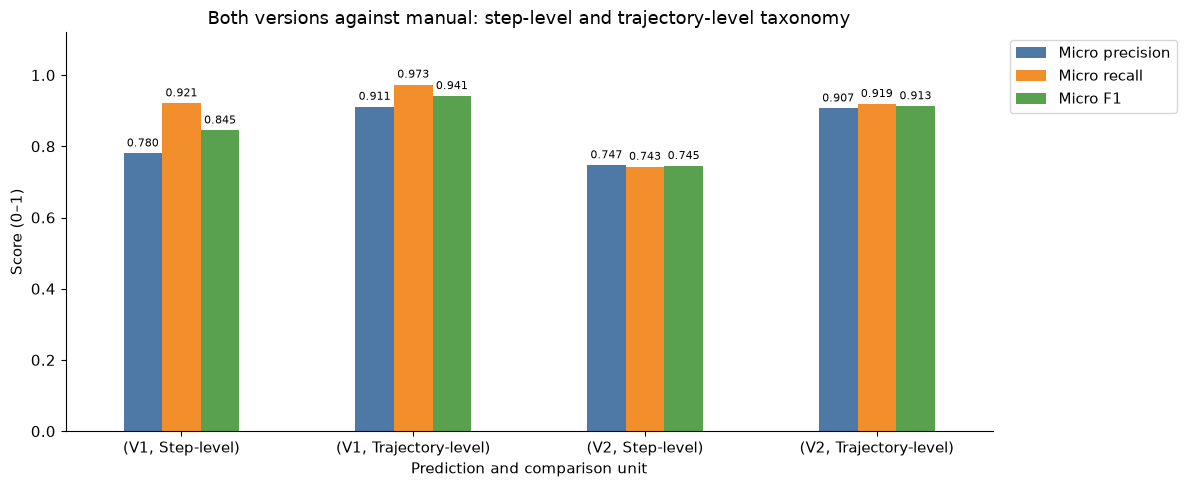

In [95]:
step_vs_trajectory_scores = pd.concat({
    v:pd.DataFrame({"Step-level":taxonomy_scores[v],"Trajectory-level":trajectory_taxonomy_scores[v]}).T
    for v in prediction_datasets
},names=["Prediction","Comparison unit"])
display(step_vs_trajectory_scores.round(4))
ax = step_vs_trajectory_scores[["Micro precision","Micro recall","Micro F1"]].plot.bar(figsize=(12,5),rot=0,color=["#4E79A7","#F28E2B","#59A14F"])
ax.set(title="Both versions against manual: step-level and trajectory-level taxonomy",ylabel="Score (0–1)",xlabel="Prediction and comparison unit",ylim=(0,1.12))
ax.legend(loc="upper left",bbox_to_anchor=(1.01,1))
for container in ax.containers:
    ax.bar_label(container,fmt="%.3f",padding=3,fontsize=8)
plt.tight_layout()
plt.show()


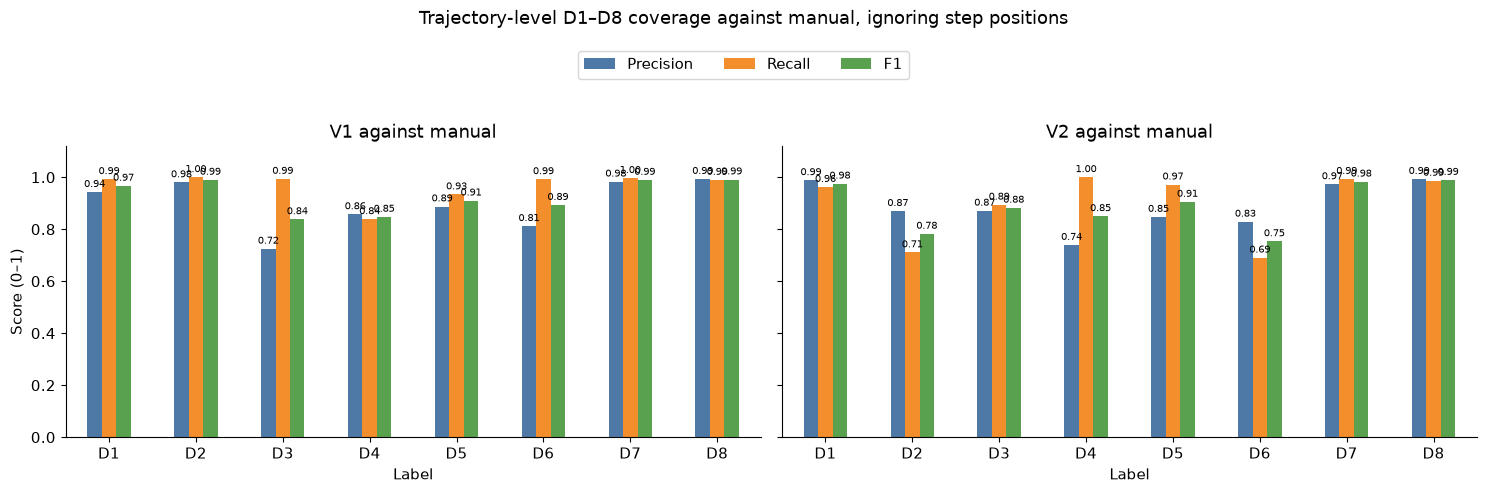

In [96]:
plot_version_prf(trajectory_taxonomy_reports,"Trajectory-level D1–D8 coverage against manual, ignoring step positions")


### 6.2 Trajectory-level visibility and category–visibility sets

Visibility presence asks whether Explicit and/or Contextual annotations appear anywhere in a trajectory. Joint sets retain category–visibility pairs, so D2/Explicit does not match D2/Contextual. Both comparisons ignore step positions and repeated occurrences. Visibility presence alone is a coarse measure; it does not establish correct visibility for every decision.


TP  FP  FN  Reference support  Prediction count  \
Prediction Label                                                          
V1         Explicit    198  18   6                204               216   
           Contextual  275  13   1                276               288   
V2         Explicit    185  12  19                204               197   
           Contextual  262   6  14                276               268   

                       Precision  Recall      F1  
Prediction Label                                  
V1         Explicit       0.9167  0.9706  0.9429  
           Contextual     0.9549  0.9964  0.9752  
V2         Explicit       0.9391  0.9069  0.9227  
           Contextual     0.9776  0.9493  0.9632

Micro precision  \
Prediction Evaluation                                              
V1         Trajectory visibility presence                 0.9385   
           Trajectory category–visibility pairs           0.7981   
V2         Trajectory visibility presence                 0.9613   
           Trajectory category–visibility pairs           0.8003   

                                                 Micro recall  Micro F1  \
Prediction Evaluation                                                     
V1         Trajectory visibility presence              0.9854    0.9614   
           Trajectory category–visibility pairs        0.8753    0.8349   
V2         Trajectory visibility presence              0.9312    0.9460   
           Trajectory category–visibility pairs        0.8301    0.8149   

                                                 Macro precision  \
Prediction Evaluation                                              
V1         Trajectory visibility presence                 0.9358   
           Trajectory category–visibility pairs           0.7561   
V2         Trajectory visibility presence                 0.9583   
           Trajectory category–visibility pairs           0.7525   

                                                 Macro recall  Macro F1  \
Prediction Evaluation                                                     
V1         Trajectory visibility presence              0.9835    0.9590   
           Trajectory category–visibility pairs        0.8392    0.7900   
V2         Trajectory visibility presence              0.9281    0.9430   
           Trajectory category–visibility pairs        0.7966    0.7658   

                                                 Weighted F1      TP     FP  \
Prediction Evaluation                                                         
V1         Trajectory visibility presence             0.9614   473.0   31.0   
           Trajectory category–visibility pairs       0.8399  1530.0  387.0   
V2         Trajectory visibility presence             0.9460   447.0   18.0   
           Trajectory category–visibility pairs       0.8168  1451.0  362.0   

                                                    FN  
Prediction Evaluation                                   
V1         Trajectory visibility presence          7.0  
           Trajectory category–visibility pairs  218.0  
V2         Trajectory visibility presence         33.0  
           Trajectory category–visibility pairs  297.0

TP  FP  FN  Reference support  Prediction count  \
Prediction Label                                                               
V1         D1 / Explicit     96   6   6                102               102   
           D1 / Contextual  168  22   6                174               190   
           D2 / Explicit     30  27  19                 49                57   
           D2 / Contextual  143  20  23                166               163   
           D3 / Explicit     28  43   8                 36                71   
           D3 / Contextual  104  59  17                121               163   
           D4 / Explicit     15  10  12                 27                25   
           D4 / Contextual   92  26  23                115               118   
           D5 / Explicit     50  26  15                 65                76   
           D5 / Contextual  141  35  24                165               176   
           D6 / Explicit     34  17   6                 40                51   
           D6 / Contextual   93  28   5                 98               121   
           D7 / Explicit    104  14  17                121               118   
           D7 / Contextual  171  29  10                181               200   
           D8 / Explicit    141   1  23                164               142   
           D8 / Contextual  120  24   4                124               144   
V2         D1 / Explicit     98  10   4                102               108   
           D1 / Contextual  153   5  21                174               158   
           D2 / Explicit     38  33  11                 49                71   
           D2 / Contextual  108  16  58                166               124   
           D3 / Explicit     23  30  13                 36                53   
           D3 / Contextual   86  22  35                121               108   
           D4 / Explicit     18  12   9                 27                30   
           D4 / Contextual  112  55   3                115               167   
           D5 / Explicit     55  28  10                 65                83   
           D5 / Contextual  144  43  21                165               187   
           D6 / Explicit     23  25  17                 40                48   
           D6 / Contextual   56  14  42                 98                70   
           D7 / Explicit    111  32  10                121               143   
           D7 / Contextual  164  15  17                181               179   
           D8 / Explicit    159  16   5                164               175   
           D8 / Contextual  103   6  21                124               109   

                            Precision  Recall      F1  
Prediction Label                                       
V1         D1 / Explicit       0.9412  0.9412  0.9412  
           D1 / Contextual     0.8842  0.9655  0.9231  
           D2 / Explicit       0.5263  0.6122  0.5660  
           D2 / Contextual     0.8773  0.8614  0.8693  
           D3 / Explicit       0.3944  0.7778  0.5234  
           D3 / Contextual     0.6380  0.8595  0.7324  
           D4 / Explicit       0.6000  0.5556  0.5769  
           D4 / Contextual     0.7797  0.8000  0.7897  
           D5 / Explicit       0.6579  0.7692  0.7092  
           D5 / Contextual     0.8011  0.8545  0.8270  
           D6 / Explicit       0.6667  0.8500  0.7473  
           D6 / Contextual     0.7686  0.9490  0.8493  
           D7 / Explicit       0.8814  0.8595  0.8703  
           D7 / Contextual     0.8550  0.9448  0.8976  
           D8 / Explicit       0.9930  0.8598  0.9216  
           D8 / Contextual     0.8333  0.9677  0.8955  
V2         D1 / Explicit       0.9074  0.9608  0.9333  
           D1 / Contextual     0.9684  0.8793  0.9217  
           D2 / Explicit       0.5352  0.7755  0.6333  
           D2 / Contextual     0.8710  0.6506  0.7448  
           D3 / Explicit       0.4340  0.6389  0.5169  
           D3 / Cont

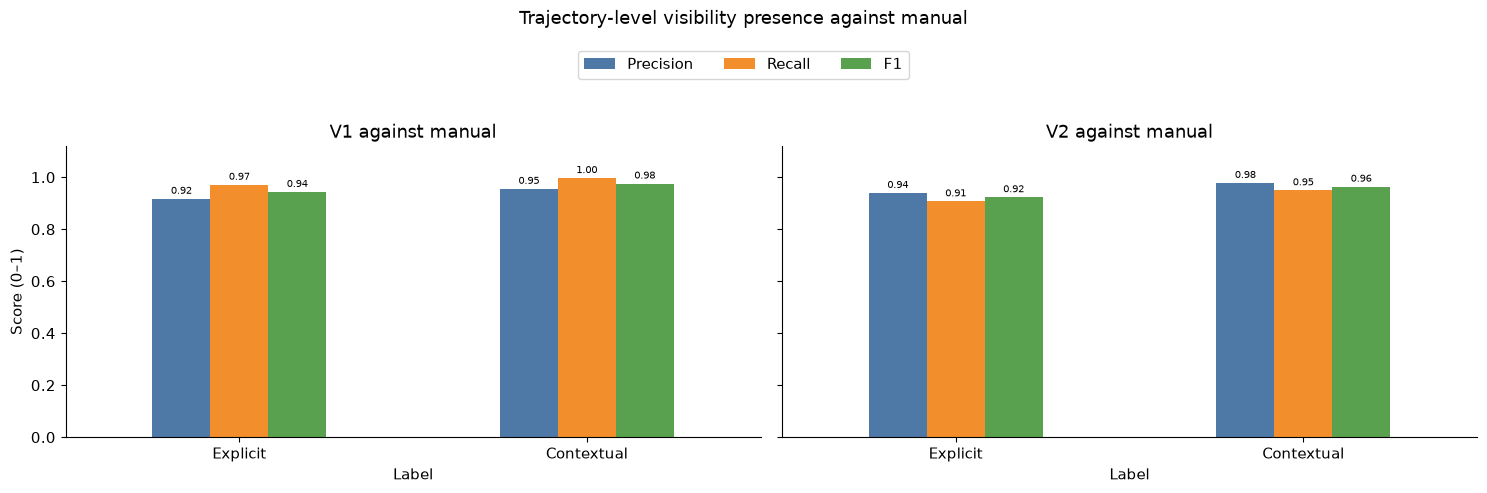

In [97]:
trajectory_visibility_reports,trajectory_visibility_scores,trajectory_joint_reports,trajectory_joint_scores = {},{},{},{}
for version,data in prediction_datasets.items():
    trajectory_visibility_reports[version],trajectory_visibility_scores[version] = compare_label_sets(trajectory_label_sets(ground_truth,"visibility"),trajectory_label_sets(data,"visibility"),VISIBILITIES)
    trajectory_joint_reports[version],trajectory_joint_scores[version] = compare_label_sets(trajectory_label_sets(ground_truth,"joint"),trajectory_label_sets(data,"joint"),joint_labels)
display(pd.concat(trajectory_visibility_reports,names=["Prediction","Label"]).round(4))
display(pd.concat({
    v:pd.DataFrame({"Trajectory visibility presence":trajectory_visibility_scores[v],"Trajectory category–visibility pairs":trajectory_joint_scores[v]}).T
    for v in prediction_datasets
},names=["Prediction","Evaluation"]).round(4))
display(pd.concat(trajectory_joint_reports,names=["Prediction","Label"]).round(4))
plot_version_prf(trajectory_visibility_reports,"Trajectory-level visibility presence against manual")


### 6.3 Per-task agreement and trajectories for review

Results are grouped by prediction version and task. The distributions summarize each version's Jaccard similarity against the manual reference. Disagreements are ranked by Jaccard within each version; the full table remains available in `trajectory_category_comparison`. The provenance column identifies tasks initially copied from V2.


Trajectories  Exact_matches  \
Prediction Task                                                           
V1         cancel-async-tasks                         20             18   
           count-dataset-tokens                       20              5   
           fix-git                                    20              5   
           git-leak-recovery                          20             14   
           headless-terminal                          20             20   
           kv-store-grpc                              20             17   
           llm-inference-batching-schedule            20             20   
           modernize-scientific-stack                 20              4   
           mteb-retrieve                              20             20   
           multi-source-data-merger                   20              4   
           portfolio-optimization                     20             16   
           pypi-server                                20              0   
           pytorch-model-recovery                     20             11   
           query-optimize                             20             20   
           sam-cell-seg                               20              3   
V2         cancel-async-tasks                         20              0   
           count-dataset-tokens                       20             20   
           fix-git                                    20              7   
           git-leak-recovery                          20             20   
           headless-terminal                          20              7   
           kv-store-grpc                              20              0   
           llm-inference-batching-schedule            20              3   
           modernize-scientific-stack                 20             20   
           mteb-retrieve                              20              2   
           multi-source-data-merger                   20             20   
           portfolio-optimization                     20             13   
           pypi-server                                20              0   
           pytorch-model-recovery                     20             20   
           query-optimize                             20             10   
           sam-cell-seg                               20             14   

                                            Exact_match_rate  Mean_Jaccard  \
Prediction Task                                                              
V1         cancel-async-tasks                           0.90        0.9829   
           count-dataset-tokens                         0.25        0.8048   
           fix-git                                      0.25        0.7983   
           git-leak-recovery                            0.70        0.9333   
           headless-terminal                            1.00        1.0000   
           kv-store-grpc                                0.85        0.9625   
           llm-inference-batching-schedule              1.00        1.0000   
           modernize-scientific-stack                   0.20        0.8071   
           mteb-retrieve                                1.00        1.0000   
           multi-source-data-merger                     0.20        0.8417   
           portfolio-optimization                       0.80        0.9107   
           pypi-server                                  0.00        0.6832   
           pytorch-model-recovery                       0.55        0.9298   
           query-optimize                               1.00        1.0000   
           sam-cell-seg                                 0.15        0.8277   
V2         cancel-async-tasks                           0.00        0.6165   
           count-dataset-tokens                         1.00        1.0000   
           fix-git                                      0.35        0.8250   
           git-leak-recovery                            1.00        1.0000   
     

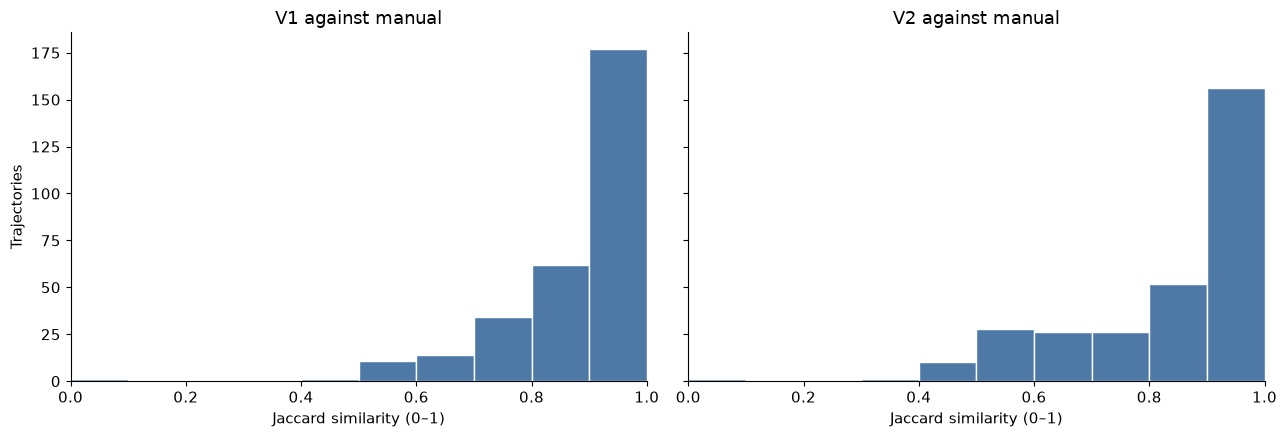

Trajectory-set disagreements against manual by prediction


,Disagreeing trajectories
Prediction,
V1,123
V2,144


,Prediction,Task,Trial ID,Manual category set,Predicted category set,Manual unique categories,Predicted unique categories,Common,Missing from prediction,Additional in prediction,...,Precision,Recall,F1,Jaccard,Exact set match,Has categories in either,Reference provenance,model,harness,resolved
0,V1,portfolio-optimization,79752f73-9823-526b-966d-578465dd7344,,"D1, D3, D5, D7, D8",0,5,,,"D1, D3, D5, D7, D8",...,0.0000,0.0000,0.0000,0.0000,False,True,Other manual tasks,gpt-5.5,terminus-2,Yes
1,V1,fix-git,2724ba31-ffb5-56fc-85e2-0988797fe00a,"D1, D5, D8","D1, D5, D6, D7",3,4,"D1, D5",D8,"D6, D7",...,0.5000,0.6667,0.5714,0.4000,False,True,Other manual tasks,claude-opus-4-8,claude-code,Yes
2,V1,fix-git,4c1b6f8e-4ba9-55d7-a4a2-c298611b6564,"D1, D5, D8","D1, D5, D6",3,3,"D1, D5",D8,D6,...,0.6667,0.6667,0.6667,0.5000,False,True,Other manual tasks,glm-5.1,claude-code,Yes
3,V1,count-dataset-tokens,643737de-2523-51e1-8dbb-4c3a96a68aa7,"D1, D2, D5, D7, D8","D1, D2, D3, D6, D7, D8",5,6,"D1, D2, D7, D8",D5,"D3, D6",...,0.6667,0.8000,0.7273,0.5714,False,True,Initially copied from V2,gpt-5.5,codex,Yes
4,V1,modernize-scientific-stack,3c2bb6d4-16d7-5ec3-8f58-7de85ff9f8d3,"D2, D4, D7, D8","D1, D2, D3, D4, D5, D7, D8",4,7,"D2, D4, D7, D8",,"D1, D3, D5",...,0.5714,1.0000,0.7273,0.5714,False,True,Initially copied from V2,gemini-3-pro-preview,terminus-2,Yes
5,V1,modernize-scientific-stack,98c576d4-ce33-5416-8e33-2751bd6ed6b6,"D2, D4, D7, D8","D1, D2, D3, D4, D5, D7, D8",4,7,"D2, D4, D7, D8",,"D1, D3, D5",...,0.5714,1.0000,0.7273,0.5714,False,True,Initially copied from V2,gemini-3.1-pro-preview,terminus-2,Yes
6,V1,pypi-server,1c0c1bcd-5062-5ff8-a3dd-7a680ee2e06d,"D1, D2, D5, D7, D8","D2, D3, D4, D5, D7, D8",5,6,"D2, D5, D7, D8",D1,"D3, D4",...,0.6667,0.8000,0.7273,0.5714,False,True,Other manual tasks,gemini-3.1-pro-preview,gemini-cli,No
7,V1,pypi-server,272e4cb0-f285-5d98-a155-eddc9d906aff,"D1, D2, D5, D7, D8","D1, D2, D3, D4, D5, D7",5,6,"D1, D2, D5, D7",D8,"D3, D4",...,0.6667,0.8000,0.7273,0.5714,False,True,Other manual tasks,grok-4.5,cursor-cli,Yes
8,V1,pypi-server,36042bfe-749e-52ff-8a4c-e424675c8515,"D1, D5, D7, D8","D1, D2, D3, D4, D5, D7, D8",4,7,"D1, D5, D7, D8",,"D2, D3, D4",...,0.5714,1.0000,0.7273,0.5714,False,True,Other manual tasks,claude-opus-4-7,claude-code,Yes
9,V1,pypi-server,758f117c-a940-5932-9a15-a8118b182ced,"D1, D5, D7, D8","D1, D2, D3, D4, D5, D7, D8",4,7,"D1, D5, D7, D8",,"D2, D3, D4",...,0.5714,1.0000,0.7273,0.5714,False,True,Other manual tasks,claude-sonnet-5,claude-code,Yes


In [98]:
trajectory_task_comparison = trajectory_category_comparison.groupby(["Prediction","Task"]).agg(
    Trajectories=("Trial ID","size"),Exact_matches=("Exact set match","sum"),
    Exact_match_rate=("Exact set match","mean"),Mean_Jaccard=("Jaccard","mean"),Mean_trajectory_F1=("F1","mean"),
)
display(trajectory_task_comparison.round(4))
fig,axes = plt.subplots(1,len(prediction_datasets),figsize=(13,4.5),sharey=True,squeeze=False)
for ax,version in zip(axes.flat,prediction_datasets):
    subset = trajectory_category_comparison.loc[trajectory_category_comparison["Prediction"].eq(version)]
    subset["Jaccard"].plot.hist(bins=[i/10 for i in range(11)],ax=ax,color="#4E79A7",edgecolor="white")
    ax.set(title=f"{version} against manual",xlabel="Jaccard similarity (0–1)",ylabel="Trajectories",xlim=(0,1))
plt.tight_layout()
plt.show()
trajectory_set_disagreements = trajectory_category_comparison.loc[~trajectory_category_comparison["Exact set match"]].sort_values(["Prediction","Jaccard","Task","Trial ID"]).reset_index(drop=True)
print("Trajectory-set disagreements against manual by prediction")
display(trajectory_set_disagreements.groupby("Prediction").size().reindex(prediction_datasets,fill_value=0).rename("Disagreeing trajectories").to_frame())
display(trajectory_set_disagreements.groupby("Prediction",group_keys=False).head(15).round(4))


In [99]:
print("Done. All analyses completed. Review the tables and figures above for detailed comparisons of GPT 300 V1, GPT 300 V2, and Manual 300 annotations against the ground truth.")

Done. All analyses completed. Review the tables and figures above for detailed comparisons of GPT 300 V1, GPT 300 V2, and Manual 300 annotations against the ground truth.
